# Bài tập 2 - Notebook gộp

Môn 121036. Người phụ trách: **Tấn Hiệp (NT), Hồng Gấm, Huỳnh Nam, Tấn Lên, Hồng Sen**.

Hoàn thành nội bộ: **18/11/2026**. Hạn nộp: **20/11/2026**.

Phần B đã gộp thuật toán, kiểm chứng và thí nghiệm của Sen và Hiệp. Phần A còn theo bộ khung. Đọc `README.md`, đề Bài tập 2 và bảng phân công của nhóm.

## 0. Chuẩn bị môi trường

Cell bên dưới do Codex tạo để import thư viện và xác định đường dẫn, ngoài phần cài đặt thuật toán. Các cell cài đặt được để trống.

**Khai báo AI cho cell chuẩn bị**

- Công cụ: Codex (OpenAI).
- Mục đích: tạo bộ khung thư mục, notebook và đường dẫn dùng chung.
- Prompt nguyên văn:

> giờ bạn tạo cái sườn giúp tôi [https://github.com/NguyenTanHiep07/xla-121036](https://github.com/NguyenTanHiep07/xla-121036) làm tiếp trong này cho dễ nha tạo mấy thư mục mấy cũ ko liên quan á bỏ qua

In [ ]:
from pathlib import Path
import math
import time

import numpy as np
import matplotlib.pyplot as plt

# Chuẩn bị đường dẫn, không cài đặt thuật toán.
thu_muc_chay = Path.cwd().resolve()
thu_muc_tim = (
    thu_muc_chay,
    thu_muc_chay / "bai_tap_2",
    thu_muc_chay.parent,
)
BT2_DIR = next(
    (p for p in thu_muc_tim if (p / "bt2_nhom.ipynb").is_file()),
    None,
)
if BT2_DIR is None:
    raise FileNotFoundError(
        "Chọn thư mục chạy là gốc repo, bai_tap_2 hoặc bai_tap_2/lam_viec."
    )
IMAGES_DIR = BT2_DIR.parent / "images"
print("Bài tập 2:", BT2_DIR)
print("Ảnh dùng chung:", IMAGES_DIR)


## Danh mục và quy ước chung

Chỉ nhóm trưởng gộp các phần đã được duyệt. Giữ một bản định nghĩa mỗi hàm. Thống nhất ảnh xám, thang mức sáng, tọa độ (row, col), cách biểu diễn seeds, ID nhãn và quy tắc ghép điểm trước khi đưa kết quả vào báo cáo.

# Phần A - Harris cổ điển và phép đo

Nguồn bàn giao: lam_viec/bt2_gam.ipynb. Người phụ trách: Hồng Gấm. Ghi commit hoặc Pull Request đã được duyệt khi gộp.

## Cài đặt - KHÔNG dùng AI

Tự viết các hàm ở những cell trống bên dưới. Chữ ký và đầu ra trong markdown là bản nhắc đặc tả của đề; không có mã thuật toán được tạo sẵn. Không dùng AI để viết, sửa lỗi hay viết lại phần này theo quy định của đề.

### `gaussian_blur(img, sigma)`

Làm mờ Gauss; được phép dùng scipy.ndimage.gaussian_filter.

### `structure_tensor(img, sigma_i, sigma_d)`

Trả (Mxx, Mxy, Myy), mỗi mảng cùng kích thước ảnh; có hệ số sigma_d**2 theo đề.

### `harris_response(img, sigma_i, sigma_d, k=0.04)`

Trả đáp ứng R dạng mảng float cùng kích thước ảnh.

### `nms_2d(response, window=3)`

Trả mảng bool đánh dấu cực đại địa phương.

### `harris_classic(img, sigma_i=2.0, sigma_d=1.4, k=0.04, thresh_rel=0.01)`

Trả mảng (N, 3): (row, col, response), giảm dần theo response.

### `repeatability(pts_a, pts_b, transform, img_shape, eps=3.0)`

Tỉ lệ trong [0, 1]. transform ánh xạ (row, col) của A sang B; chỉ tính điểm chiếu còn trong ảnh B.

# Phần A1 - Harris-Laplace

Nguồn bàn giao: lam_viec/bt2_nam.ipynb. Người phụ trách: Huỳnh Nam. Ghi commit hoặc Pull Request đã được duyệt khi gộp.

## Cài đặt - KHÔNG dùng AI

Tự viết các hàm ở những cell trống bên dưới. Chữ ký và đầu ra trong markdown là bản nhắc đặc tả của đề; không có mã thuật toán được tạo sẵn. Không dùng AI để viết, sửa lỗi hay viết lại phần này theo quy định của đề.

### `scale_pyramid(sigma0=1.2, xi=1.2, n_levels=10)`

Trả mảng 1D các sigma theo đặc tả.

### `log_normalized(img, sigma)`

Trả độ lớn Laplacian chuẩn hóa theo tỉ lệ, sigma**2 * |Lxx + Lyy|.

### `harris_laplace(img, sigmas, k=0.04, thresh_rel=0.01, log_thresh=0.0)`

Trả mảng (N, 4): (row, col, sigma, response). Giữ cực đại LoG theo trục tỉ lệ theo đề.

# Phần A2 - ANMS

Nguồn bàn giao: lam_viec/bt2_len.ipynb. Người phụ trách: Tấn Lên. Ghi commit hoặc Pull Request đã được duyệt khi gộp.

## Cài đặt - KHÔNG dùng AI

Tự viết các hàm ở những cell trống bên dưới. Chữ ký và đầu ra trong markdown là bản nhắc đặc tả của đề; không có mã thuật toán được tạo sẵn. Không dùng AI để viết, sửa lỗi hay viết lại phần này theo quy định của đề.

### `anms(points, n_keep, c_robust=0.9)`

Đầu vào (N, 3) từ Harris cổ điển; đầu ra các điểm được giữ, sắp theo bán kính giảm dần.

### `top_n(points, n_keep)`

Đối chứng lấy n_keep điểm mạnh nhất, đầu ra (n_keep, 3).

### Phép đo grid_occupancy dùng chung

Gộp hàm được cung cấp hoặc bản tự viết đã được duyệt từ Lên nếu phần kiểm chứng/thí nghiệm sử dụng. Ghi nguồn rõ ràng.

# Phần B - Region Growing và độ nhạy hạt giống

Nguồn: Hồng Sen, `lam_viec/bt2_sen.ipynb`, commit `4cb91da` (PR #43).

## Cài đặt - KHÔNG dùng AI

Tự viết các hàm ở những cell trống bên dưới. Chữ ký và đầu ra trong markdown là bản nhắc đặc tả của đề; không có mã thuật toán được tạo sẵn. Không dùng AI để viết, sửa lỗi hay viết lại phần này theo quy định của đề.

### `region_growing_classic(img, seeds, T, order="stack")`

order: stack hoặc queue. Trả labels int32, -1 cho pixel chưa thuộc vùng nào.

In [2]:
def region_growing_classic(img, seeds, T, order="stack"):
    """
    Region Growing cổ điển.

    Parameters
    ----------
    img : ndarray
        Ảnh xám 2 chiều.
    seeds : iterable
        Danh sách tọa độ (row, col).
    T : float
        Ngưỡng chênh lệch cường độ.
    order : str
        "stack" (LIFO) hoặc "queue" (FIFO).

    Returns
    -------
    labels : ndarray, dtype=int32
        Nhãn vùng; -1 là pixel chưa được gán.
    """
    img = np.asarray(img, dtype=np.float64)

    if img.ndim != 2:
        raise ValueError("img phải là ảnh xám 2 chiều.")

    if not np.isfinite(img).all():
        raise ValueError("img không được chứa NaN hoặc Inf.")

    if not np.isscalar(T) or not np.isfinite(T) or T < 0:
        raise ValueError("T phải là số hữu hạn không âm.")

    if order not in ("stack", "queue"):
        raise ValueError("order chỉ nhận 'stack' hoặc 'queue'.")

    height, width = img.shape
    labels = np.full((height, width), -1, dtype=np.int32)

    seeds = [(int(r), int(c)) for r, c in seeds]

    if len(set(seeds)) != len(seeds):
        raise ValueError("Các seed không được trùng nhau.")

    for r, c in seeds:
        if not (0 <= r < height and 0 <= c < width):
            raise ValueError(f"Seed {(r, c)} nằm ngoài ảnh.")

    # Lân cận 4 hướng.
    neighbors = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    for region_id, (sr, sc) in enumerate(seeds):

        # Bỏ qua seed đã thuộc vùng được xử lý trước đó.
        if labels[sr, sc] != -1:
            continue

        labels[sr, sc] = region_id

        frontier = [(sr, sc)]
        head = 0

        region_sum = float(img[sr, sc])
        region_count = 1
        region_mean = region_sum

        while (frontier if order == "stack" else head < len(frontier)):

            if order == "stack":
                r, c = frontier.pop()
            else:
                r, c = frontier[head]
                head += 1

            for dr, dc in neighbors:
                nr, nc = r + dr, c + dc

                if not (0 <= nr < height and 0 <= nc < width):
                    continue

                if labels[nr, nc] != -1:
                    continue

                if abs(float(img[nr, nc]) - region_mean) <= T:
                    labels[nr, nc] = region_id

                    frontier.append((nr, nc))

                    region_sum += float(img[nr, nc])
                    region_count += 1
                    region_mean = region_sum / region_count

    return labels

### `seed_sensitivity(img, seeds, segment_fn, n_trials=20, jitter=3)`

Trả bản đồ tần suất đổi nhãn khi nhiễu vị trí hạt giống, theo định nghĩa đề.

In [3]:
def seed_sensitivity(img, seeds, segment_fn, n_trials=20, jitter=3):
    if n_trials <= 0:
        raise ValueError("n_trials phải lớn hơn 0.")
    if jitter < 0:
        raise ValueError("jitter không được âm.")

    img = np.asarray(img)
    seeds = np.asarray(seeds, dtype=np.int32)

    if img.ndim < 2:
        raise ValueError("Ảnh phải có ít nhất 2 chiều.")
    if seeds.ndim != 2 or seeds.shape[1] != 2 or len(seeds) == 0:
        raise ValueError("seeds phải có dạng danh sách (row, col).")

    height, width = img.shape[:2]

    if np.any(seeds[:, 0] < 0) or np.any(seeds[:, 0] >= height):
        raise ValueError("Seed có tọa độ row ngoài ảnh.")
    if np.any(seeds[:, 1] < 0) or np.any(seeds[:, 1] >= width):
        raise ValueError("Seed có tọa độ col ngoài ảnh.")
    if len(np.unique(seeds, axis=0)) != len(seeds):
        raise ValueError("Các seed ban đầu không được trùng nhau.")

    def get_labels(result):
        if isinstance(result, tuple):
            result = result[0]
        result = np.asarray(result)

        if result.shape != (height, width):
            raise ValueError("segment_fn phải trả về bản đồ nhãn H x W.")

        return result

    baseline = get_labels(segment_fn(img, seeds.tolist()))

    changed_count = np.zeros((height, width), dtype=np.float32)
    rng = np.random.default_rng()

    for trial in range(n_trials):
        perturbed_seeds = []
        used_positions = set()

        for seed in seeds:
            row, col = map(int, seed)
            chosen_seed = None

            for attempt in range(100):
                dr = int(rng.integers(-jitter, jitter + 1))
                dc = int(rng.integers(-jitter, jitter + 1))

                new_row = int(np.clip(row + dr, 0, height - 1))
                new_col = int(np.clip(col + dc, 0, width - 1))

                candidate = (new_row, new_col)

                if candidate not in used_positions:
                    chosen_seed = candidate
                    break

            if chosen_seed is None:
                candidate = (row, col)
                if candidate not in used_positions:
                    chosen_seed = candidate
                else:
                    raise ValueError("Không tạo được các seed riêng biệt.")

            perturbed_seeds.append(chosen_seed)
            used_positions.add(chosen_seed)

        trial_labels = get_labels(
            segment_fn(img, perturbed_seeds)
        )

        changed_count += (trial_labels != baseline)

    sensitivity_map = changed_count / n_trials

    return sensitivity_map.astype(np.float32)

# Phần B - SRG và ảnh tiến trình

Nguồn: Tấn Hiệp, `lam_viec/bt2_hiep.ipynb`, commit `8db1f8d` (PR #44).

## Cài đặt - KHÔNG dùng AI

Tự viết các hàm ở những cell trống bên dưới. Chữ ký và đầu ra trong markdown là bản nhắc đặc tả của đề; không có mã thuật toán được tạo sẵn. Không dùng AI để viết, sửa lỗi hay viết lại phần này theo quy định của đề.

### `srg(img, seeds, connectivity=4, stale="lazy", tie="insertion")`

Trả (labels, boundary_mask); mọi pixel có nhãn >= 0. Hỗ trợ hai chế độ stale và các quy tắc phá hòa theo đề.

In [4]:
from heapq import heappop, heappush

TIE_RANDOM_SEED = 0  

def _parse_seeds(seeds, h, w):
    """Mỗi hạt giống là một pixel (row, col) hoặc một tập pixel [(row, col), ...]."""
    seed_sets = []
    for seed in seeds:
        arr = np.asarray(seed)
        if arr.ndim == 1:
            arr = arr.reshape(1, -1)
        if arr.ndim != 2 or arr.shape[1] != 2 or len(arr) == 0:
            raise ValueError("Mỗi seed phải là (row, col) hoặc danh sách (row, col)")
        if not np.issubdtype(arr.dtype, np.integer):
            raise ValueError("Tọa độ seed phải là số nguyên")
        points = [(int(r), int(c)) for r, c in arr]
        for r, c in points:
            if not (0 <= r < h and 0 <= c < w):
                raise ValueError("Seed nằm ngoài ảnh")
        seed_sets.append(points)
    return seed_sets


def _srg(img, seeds, connectivity, stale, tie, n_frames):
    img = np.asarray(img, dtype=float)
    if img.ndim != 2 or img.size == 0:
        raise ValueError("img phải là ảnh xám 2D không rỗng")
    if connectivity not in (4, 8):
        raise ValueError("connectivity phải là 4 hoặc 8")
    if stale not in ("lazy", "frozen"):
        raise ValueError("stale phải là lazy hoặc frozen")
    if tie not in ("insertion", "raster", "random"):
        raise ValueError("tie không hợp lệ")

    h, w = img.shape
    seed_sets = _parse_seeds(seeds, h, w)
    all_seed_points = [p for points in seed_sets for p in points]
    if not seed_sets or len(set(all_seed_points)) != len(all_seed_points):
        raise ValueError("Cần ít nhất một seed và các seed không được trùng pixel")

    offsets = [(-1, 0), (0, -1), (0, 1), (1, 0)]
    if connectivity == 8:
        offsets += [(-1, -1), (-1, 1), (1, -1), (1, 1)]

    labels = np.full((h, w), -1, dtype=np.int32)
    boundary = np.zeros((h, w), dtype=bool)
    seed_values = []
    totals = []
    counts = []
    for i, points in enumerate(seed_sets):
        for p in points:
            labels[p] = i
        values = [img[p] for p in points]
        seed_values.append(sum(values) / len(values))
        totals.append(sum(values))
        counts.append(len(values))

    heap = []
    queued = {}
    keys = {}
    rng = np.random.default_rng(TIE_RANDOM_SEED)
    frames = []
    filled = len(all_seed_points)

    def neighbors(r, c):
        for dr, dc in offsets:
            rr, cc = r + dr, c + dc
            if 0 <= rr < h and 0 <= cc < w:
                yield rr, cc

    def key(point):
        if point not in keys:
            if tie == "insertion":
                keys[point] = len(keys)
            elif tie == "raster":
                keys[point] = point[0] * w + point[1]
            else:
                keys[point] = float(rng.random())
        return keys[point]

    region_keys = [min(key(p) for p in points) for points in seed_sets]

    def candidate(point):
        regions = {
            int(labels[p]) for p in neighbors(*point) if labels[p] >= 0
        }
        value = img[point]
        options = []
        for i in regions:
            ref = seed_values[i] if stale == "frozen" else totals[i] / counts[i]
            options.append((abs(value - ref), region_keys[i], i))
        distance, _, region = min(options)
        return distance, region, len(regions) > 1

    def enqueue(point, distance):
        entry = (distance, key(point), point)
        if queued.get(point) != entry:
            queued[point] = entry
            heappush(heap, entry)

    def add_neighbors(point):
        for p in neighbors(*point):
            if labels[p] == -1:
                distance, _, _ = candidate(p)
                enqueue(p, distance)

    def save_frames():
        while len(frames) < n_frames and filled * n_frames >= (len(frames) + 1) * img.size:
            frames.append(labels.copy())

    for point in all_seed_points:
        add_neighbors(point)
    save_frames()

    while heap:
        entry = heappop(heap)
        old_distance, _, point = entry
        if queued.get(point) != entry:
            continue
        del queued[point]

        distance, region, is_boundary = candidate(point)
        if distance != old_distance:
            enqueue(point, distance)
            continue

        labels[point] = region
        boundary[point] = is_boundary
        totals[region] += img[point]
        counts[region] += 1
        filled += 1
        save_frames()
        add_neighbors(point)

    return labels, boundary, frames


def srg(img, seeds, connectivity=4, stale="lazy", tie="insertion"):
    """Seeded Region Growing (Adams & Bischof 1994), công thức (5). Dùng heapq.

    seeds: danh sách hạt giống; mỗi hạt giống là một pixel (row, col)
           hoặc một tập pixel [(row, col), ...]. Nhãn i ứng với seeds[i].
    stale: "lazy"   -> tính lại delta khi pop, đẩy lại nếu đã cũ
           "frozen" -> delta theo giá trị (trung bình) của hạt giống
    tie:   quy tắc phá hoà tất định: "insertion" | "raster" | "random"
           ("random" dùng seed cố định TIE_RANDOM_SEED)
    -> (labels, boundary_mask); mọi pixel đều có nhãn >= 0.
    """
    labels, boundary, _ = _srg(img, seeds, connectivity, stale, tie, 0)
    return labels, boundary

### `srg_step_frames(img, seeds, n_frames=8, **kwargs)`

Trả danh sách n_frames ảnh nhãn tại các mốc tiến trình.

In [5]:
def srg_step_frames(img, seeds, n_frames=8, **kwargs):
    """Ảnh nhãn tại các mốc tiến trình (12%, 25%, ...).

    kwargs: connectivity, stale, tie như srg.
    -> danh sách n_frames mảng nhãn (bản sao), frame cuối là kết quả cuối.
    """
    if not isinstance(n_frames, (int, np.integer)) or n_frames < 1:
        raise ValueError("n_frames phải là số nguyên dương")
    connectivity = kwargs.pop("connectivity", 4)
    stale = kwargs.pop("stale", "lazy")
    tie = kwargs.pop("tie", "insertion")
    if kwargs:
        raise TypeError(f"Tham số không hợp lệ: {', '.join(kwargs)}")
    _, _, frames = _srg(img, seeds, connectivity, stale, tie, n_frames)
    return frames

## Kiểm chứng cài đặt

Mã A1-A5 và B1-B5 bên dưới là thứ tự kiểm chứng trong mục 3.7 / 4.5 của đề. Điền dữ liệu kiểm tra, số đo và output thực tế. Các ô mã hiện để trống.

### Kiểm chứng A1 - Bàn cờ tổng hợp

Giao điểm trong, sai số định vị ≤ 1 px. Người phụ trách: Gấm.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

**Nhận xét kiểm chứng:**

- Kết quả thực tế: 
- Đạt/chưa đạt và lý do: 

### Kiểm chứng A2 - Xoay ảnh 30 độ

Báo số điểm và repeatability bằng phép biến đổi tọa độ đúng. Người phụ trách: Gấm.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

**Nhận xét kiểm chứng:**

- Kết quả thực tế: 
- Đạt/chưa đạt và lý do: 

### Kiểm chứng A3 - Phóng to 3 lần

Báo repeatability Harris cổ điển và Harris-Laplace. Người phụ trách: Nam.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

**Nhận xét kiểm chứng:**

- Kết quả thực tế: 
- Đạt/chưa đạt và lý do: 

### Kiểm chứng A4 - Đối chiếu OpenCV

Dùng cv2.cornerHarris trong cell đối chiếu; báo điểm khớp trong 2-3 px. Người phụ trách: Gấm.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

**Nhận xét kiểm chứng:**

- Kết quả thực tế: 
- Đạt/chưa đạt và lý do: 

### Kiểm chứng A5 - Độ phủ ANMS

Cùng ứng viên, cùng N, so top_n và anms bằng grid_occupancy. Người phụ trách: Lên.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

**Nhận xét kiểm chứng:**

- Kết quả thực tế: 
- Đạt/chưa đạt và lý do: 

### Dữ liệu chung cho B1–B4 và so sánh Region Growing với SRG

In [6]:
import cv2

image_path = IMAGES_DIR / "uneven_lighting.jpg"
test_img = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
if test_img is None:
    raise FileNotFoundError(str(image_path))

test_seeds = [(50, 360), (120, 120)]
T_test = 15

### Kiểm chứng B1 - Phân hoạch đầy đủ

Kiểm tra mọi labels của SRG >= 0. Người phụ trách: Sen.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: ChatGPT (OpenAI).
- Mục đích: Hỗ trợ xây dựng cell kiểm chứng kết quả phân hoạch ảnh bằng SRG
- Prompt nguyên văn: Hãy hỗ trợ kiểm tra kết quả SRG, bao gồm kích thước bản đồ nhãn, kiểu dữ liệu, số pixel chưa được gán nhãn và kích thước bản đồ biên. Đối chiếu kết quả với yêu cầu kiểm chứng B1.
- Phần đã tự sửa và kiểm tra: Đã chạy cell, kiểm tra các điều kiện assert. Kết quả: 307.200 pixel đều được gán nhãn, không còn pixel chưa gán nhãn. B1: PASS.

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

In [7]:
labels_srg, boundary_mask = srg(
    test_img,
    test_seeds,
    connectivity=4,
    stale="lazy",
    tie="insertion"
)

unassigned_count = np.count_nonzero(labels_srg < 0)

print("Image shape:", test_img.shape)
print("Labels shape:", labels_srg.shape)
print("Labels dtype:", labels_srg.dtype)
print("Các nhãn xuất hiện:", np.unique(labels_srg))
print("Unassigned pixels:", unassigned_count)
print("Boundary pixels:", np.count_nonzero(boundary_mask))

assert labels_srg.shape == test_img.shape
assert labels_srg.dtype == np.int32
assert boundary_mask.shape == test_img.shape
assert np.all(labels_srg >= 0)

print("B1: PASS")

Image shape: (480, 640)
Labels shape: (480, 640)
Labels dtype: int32
Các nhãn xuất hiện: [0 1]
Unassigned pixels: 0
Boundary pixels: 1045
B1: PASS


**Nhận xét kiểm chứng:**

- Kết quả thực tế: SRG phân hoạch toàn bộ ảnh thành 2 vùng, không còn pixel chưa được gán nhãn. Có 1.045 pixel biên.
- Đạt/chưa đạt và lý do: Đạt. Kích thước bản đồ nhãn khớp ảnh đầu vào, kiểu dữ liệu đúng int32 và tất cả pixel đều có nhãn hợp lệ.

### Kiểm chứng B2 - Số vùng

Kiểm tra số nhãn phân biệt bằng số hạt giống hợp lệ. Người phụ trách: Sen.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: ChatGPT (OpenAI).
- Mục đích: Hỗ trợ xây dựng cell kiểm tra số vùng SRG có bằng số hạt giống hay không.
- Prompt nguyên văn: Hãy hỗ trợ viết cell kiểm chứng B2, đếm số nhãn phân biệt trong kết quả SRG, so sánh với số lượng hạt giống và kiểm tra điều kiện hai số bằng nhau.
- Phần đã tự sửa và kiểm tra:Đã chạy cell với 2 hạt giống. Kết quả có 2 vùng, nhãn [0, 1]. B2: PASS. 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

In [8]:
# B2 - Kiểm chứng số vùng bằng số seed

num_regions = len(np.unique(labels_srg))
num_seeds = len(test_seeds)

print("Số seed:", num_seeds)
print("Số vùng thực tế:", num_regions)
print("Các nhãn:", np.unique(labels_srg))

assert num_regions == num_seeds

print("B2: PASS")

Số seed: 2
Số vùng thực tế: 2
Các nhãn: [0 1]
B2: PASS


**Nhận xét kiểm chứng:**

- Kết quả thực tế: Có 2 seed và 2 vùng được tạo ra, tương ứng nhãn 0 và 1.
- Đạt/chưa đạt và lý do: Đạt. Số vùng thực tế bằng số seed ban đầu.

### Kiểm chứng B3 - Đảo thứ tự hạt giống

So kết quả sau khi thống nhất lại ý nghĩa ID nhãn; ghi quy tắc phá hòa. Người phụ trách: Sen.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: ChatGPT (OpenAI).
- Mục đích: Hỗ trợ thiết kế cell kiểm chứng ảnh hưởng của thứ tự hạt giống và quy tắc phá hòa đến kết quả SRG.
- Prompt nguyên văn: Hãy hỗ trợ xây dựng cell kiểm chứng B3 bằng cách đảo thứ tự hạt giống, quy đổi ID nhãn về thứ tự ban đầu rồi đếm số pixel thay đổi. Kiểm tra trên ảnh thật và ảnh phẳng với các quy tắc tie insertion, raster và random.
- Phần đã tự sửa và kiểm tra: Đã chạy thử trên ảnh thật và ảnh phẳng, so sánh số pixel khác nhau giữa kết quả ban đầu và kết quả sau khi đảo thứ tự hạt giống.

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

In [9]:
# ===== B3 - Bất biến thứ tự hạt giống =====
# Chạy srg với danh sách hạt giống và với chính danh sách đó đảo ngược, rồi đưa ID nhãn
# của lần đảo về ID của lần gốc trước khi so (seed thứ i của lần đảo là seed thứ n-1-i của lần gốc).


def doi_nhan_ve_thu_tu_goc(nhan_dao, so_hat):
    """Lần đảo: nhãn k ứng với seed gốc thứ (so_hat - 1 - k)."""
    nhan_goc = np.full_like(nhan_dao, -1)
    for k in range(so_hat):
        nhan_goc[nhan_dao == k] = so_hat - 1 - k
    return nhan_goc


def so_sanh_dao_thu_tu(anh, cac_hat, **cau_hinh):
    nhan_xuoi, _ = srg(anh, cac_hat, **cau_hinh)
    nhan_dao, _ = srg(anh, list(reversed(cac_hat)), **cau_hinh)
    nhan_dao = doi_nhan_ve_thu_tu_goc(nhan_dao, len(cac_hat))
    assert (nhan_dao >= 0).all()
    return int(np.count_nonzero(nhan_xuoi != nhan_dao))


# 1) Ảnh thật uneven_lighting.jpg, hai hạt giống như B1, đủ 3 quy tắc phá hòa
print(f"Ảnh thật {test_img.shape}, seeds = {test_seeds}, liên thông 4, stale = lazy")
for luat_hoa in ("insertion", "raster", "random"):
    so_khac = so_sanh_dao_thu_tu(test_img, test_seeds, connectivity=4, stale="lazy", tie=luat_hoa)
    print(f"  tie = {luat_hoa:<9}: {so_khac} pixel khác ({100 * so_khac / test_img.size:.4f}%)")

# 2) Ảnh phẳng: mọi delta bằng nhau, chỉ còn quy tắc phá hòa quyết định
anh_phang = np.full((40, 60), 128.0)
hat_phang = [(20, 15), (20, 45)]
print(f"\nẢnh phẳng 40x60, seeds = {hat_phang}, liên thông 4, stale = lazy")
for luat_hoa in ("insertion", "raster", "random"):
    so_khac = so_sanh_dao_thu_tu(anh_phang, hat_phang, connectivity=4, stale="lazy", tie=luat_hoa)
    print(f"  tie = {luat_hoa:<9}: {so_khac} pixel khác ({100 * so_khac / anh_phang.size:.2f}%)")

print("\nB3: DONE")

Ảnh thật (480, 640), seeds = [(50, 360), (120, 120)], liên thông 4, stale = lazy


  tie = insertion: 0 pixel khác (0.0000%)


  tie = raster   : 0 pixel khác (0.0000%)


  tie = random   : 0 pixel khác (0.0000%)

Ảnh phẳng 40x60, seeds = [(20, 15), (20, 45)], liên thông 4, stale = lazy
  tie = insertion: 40 pixel khác (1.67%)
  tie = raster   : 0 pixel khác (0.00%)
  tie = random   : 1297 pixel khác (54.04%)

B3: DONE


**Nhận xét kiểm chứng B3**

- Sau khi đảo thứ tự hạt giống, đổi ID nhãn về thứ tự gốc trước khi đếm pixel khác nhau. Bảng phía trên dùng bản SRG chung của Hiệp với `TIE_RANDOM_SEED = 0`.
- Trên ảnh phẳng, mọi δ bằng nhau. Quy tắc phá hòa có thể làm thay đổi thứ tự kết nạp và hình dạng vùng khi đổi thứ tự hạt giống.

### Kiểm chứng B4 - Stack, queue và SRG

Cùng ảnh, cùng seeds; báo số pixel khác nhau trong từng cặp. Người phụ trách: Sen.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: ChatGPT (OpenAI).
- Mục đích: Hỗ trợ xây dựng cell so sánh kết quả phân vùng của Region Growing sử dụng stack, queue và SRG.
- Prompt nguyên văn: Hãy hỗ trợ xây dựng cell kiểm chứng B4 để so sánh Region Growing với stack, Region Growing với queue và SRG trên cùng ảnh, cùng hạt giống và cùng ngưỡng T. Tính số pixel khác nhau giữa từng cặp phương pháp và hiển thị kết quả trực quan bằng ba hình ảnh.
- Phần đã tự sửa và kiểm tra: Đã chạy cell, kiểm tra số pixel khác nhau giữa từng cặp phương pháp và hiển thị ba kết quả phân vùng để đối chiếu.

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

Ảnh (480, 640) = 307200 pixel, seeds = [(50, 360), (120, 120)], T = 15, SRG: liên thông 4, lazy, insertion
  stack : pixel -1 =  188647, diện tích theo nhãn = {0: 56298, 1: 62255}
  queue : pixel -1 =  186944, diện tích theo nhãn = {0: 58673, 1: 61583}
  SRG   : pixel -1 =       0, diện tích theo nhãn = {0: 120309, 1: 186891}

cặp               tổng khác     khác nhãn khi cả hai đã gán   chỉ một bên gán
stack vs queue         9773                      0 / 114518              9773
stack vs SRG         188649                      2 / 118553            188647
queue vs SRG         186944                      0 / 120256            186944


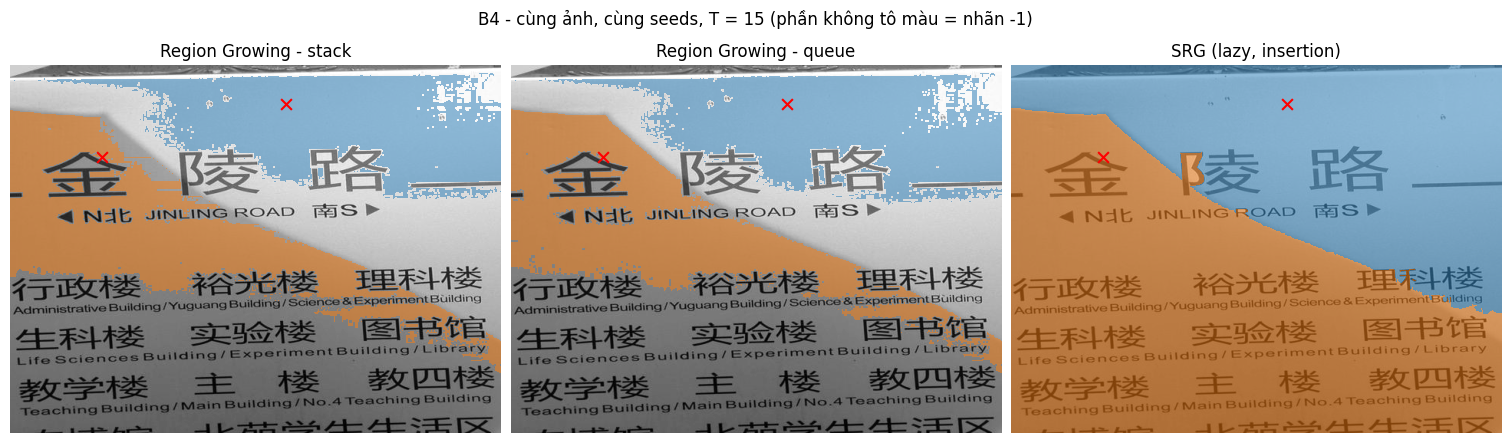

B4: DONE


In [10]:
# ===== B4 - So Region Growing (stack / queue) với SRG =====
# Cùng ảnh, cùng seeds, cùng ngưỡng T. ID nhãn của cả ba phương pháp đều là chỉ số seed trong danh sách,
# nên đã thẳng hàng, không cần đổi ID. Region Growing để -1 ở pixel không thuộc vùng nào còn SRG
# thì gán hết, nên tách riêng hai phần: pixel -1 và pixel khác nhãn trên phần cả hai đều đã gán.
T_B4 = T_test
nhan_stack = region_growing_classic(test_img, test_seeds, T=T_B4, order="stack")
nhan_queue = region_growing_classic(test_img, test_seeds, T=T_B4, order="queue")
nhan_srg, bien_srg = srg(test_img, test_seeds, connectivity=4, stale="lazy", tie="insertion")

print(f"Ảnh {test_img.shape} = {test_img.size} pixel, seeds = {test_seeds}, T = {T_B4}, "
      f"SRG: liên thông 4, lazy, insertion")
for ten, nhan in (("stack", nhan_stack), ("queue", nhan_queue), ("SRG", nhan_srg)):
    dien_tich = {k: int((nhan == k).sum()) for k in range(len(test_seeds))}
    print(f"  {ten:<6}: pixel -1 = {int((nhan == -1).sum()):>7}, diện tích theo nhãn = {dien_tich}")


def so_sanh_cap(nhan_a, nhan_b):
    tong_khac = int(np.count_nonzero(nhan_a != nhan_b))
    ca_hai_da_gan = (nhan_a >= 0) & (nhan_b >= 0)
    khac_khi_ca_hai_gan = int(np.count_nonzero((nhan_a != nhan_b) & ca_hai_da_gan))
    chi_mot_ben_gan = int(np.count_nonzero((nhan_a >= 0) != (nhan_b >= 0)))
    return tong_khac, khac_khi_ca_hai_gan, int(ca_hai_da_gan.sum()), chi_mot_ben_gan


print(f"\n{'cặp':<16}{'tổng khác':>11}{'khác nhãn khi cả hai đã gán':>32}{'chỉ một bên gán':>18}")
for ten, a, b in (("stack vs queue", nhan_stack, nhan_queue),
                  ("stack vs SRG", nhan_stack, nhan_srg),
                  ("queue vs SRG", nhan_queue, nhan_srg)):
    tong, khac_gan, so_gan, mot_ben = so_sanh_cap(a, b)
    print(f"{ten:<16}{tong:>11}{f'{khac_gan} / {so_gan}':>32}{mot_ben:>18}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), constrained_layout=True)
for ax, (ten, nhan) in zip(axes, (("Region Growing - stack", nhan_stack),
                                  ("Region Growing - queue", nhan_queue),
                                  ("SRG (lazy, insertion)", nhan_srg))):
    ax.imshow(test_img, cmap="gray")
    ax.imshow(np.ma.masked_less(nhan, 0), cmap="tab10", alpha=0.5, vmin=0, vmax=9)
    for r, c in test_seeds:
        ax.scatter(c, r, marker="x", s=60, c="red")
    ax.set_title(ten)
    ax.axis("off")
fig.suptitle(f"B4 - cùng ảnh, cùng seeds, T = {T_B4} (phần không tô màu = nhãn -1)")
plt.show()
print("B4: DONE")

**Nhận xét kiểm chứng B4**

- **stack vs queue** có 9.773 pixel khác, gồm 9.773 pixel chỉ một bên gán và 0/114.518 pixel khác nhãn trên phần cả hai đã gán.
- **stack vs SRG** có 188.649 pixel khác, gồm 188.647 pixel chỉ một bên gán và 2/118.553 pixel khác nhãn trên phần cả hai đã gán.
- **queue vs SRG** có 186.944 pixel khác, gồm 186.944 pixel chỉ một bên gán và 0/120.256 pixel khác nhãn trên phần cả hai đã gán.

Cả ba phương pháp dùng cùng ảnh và cùng hạt giống. Stack và queue dùng T = 15. Sự khác biệt chủ yếu nằm ở độ phủ vì SRG gán nhãn toàn ảnh.

### Kiểm chứng B5 - Ảnh phẳng, hai seeds

Mô tả hình dạng vùng với quy tắc phá hòa. Người phụ trách: Hiệp.

Cấu hình: ảnh 40x60, mọi pixel = 128.0, hạt giống = [(20, 15), (20, 45)], TIE_RANDOM_SEED = 0

cấu hình                    S0    S1  hộp bao vùng 0    hộp bao vùng 1     chia dọc  khớp gần nhất %  biên  t (ms)


lazy/insertion/4          1240  1160  r0-39,c0-30       r0-39,c31-59             31            100.0    40    13.1
frozen/insertion/4        1240  1160  r0-39,c0-30       r0-39,c31-59             31            100.0    40    12.5
lazy/raster/4             2399     1  r0-39,c0-59       r20-20,c45-45          None             50.9     4    12.7
frozen/raster/4           2399     1  r0-39,c0-59       r20-20,c45-45          None             50.9     4    12.4
lazy/random/4             1746   654  r0-39,c0-59       r0-28,c22-59           None             74.2    72    13.9
frozen/random/4           1746   654  r0-39,c0-59       r0-28,c22-59           None             74.2    72    13.6


lazy/insertion/8          1276  1124  r0-39,c0-36       r0-39,c31-59           None             99.5    51    27.8


frozen/insertion/8        1276  1124  r0-39,c0-36       r0-39,c31-59           None             99.5    51    27.8
lazy/raster/8             2399     1  r0-39,c0-59       r20-20,c45-45          None             50.9     8    28.0
frozen/raster/8           2399     1  r0-39,c0-59       r20-20,c45-45          None             50.9     8    27.3


lazy/random/8              532  1868  r0-39,c0-18       r0-39,c9-59            None             72.2   102    29.5


frozen/random/8            532  1868  r0-39,c0-18       r0-39,c9-59            None             72.2   102    29.0
liên thông 4, tie=insertion: số pixel khác nhau lazy vs frozen = 0
liên thông 4, tie=raster   : số pixel khác nhau lazy vs frozen = 0
liên thông 4, tie=random   : số pixel khác nhau lazy vs frozen = 0
liên thông 8, tie=insertion: số pixel khác nhau lazy vs frozen = 0
liên thông 8, tie=raster   : số pixel khác nhau lazy vs frozen = 0
liên thông 8, tie=random   : số pixel khác nhau lazy vs frozen = 0
insertion vs raster: 1159 pixel khác nhau (48.3%)
insertion vs random: 612 pixel khác nhau (25.5%)
raster vs random: 653 pixel khác nhau (27.2%)


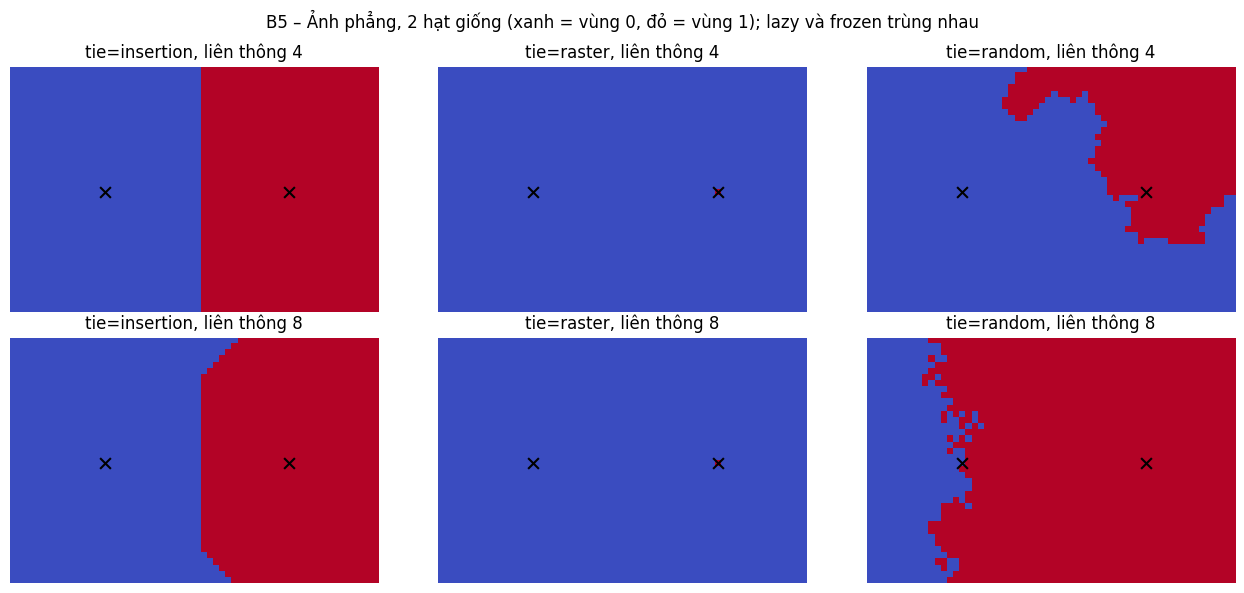

ĐẠT: 12 cấu hình đều phủ hết ảnh, đúng 2 vùng, chạy lại cho cùng kết quả.
tie                mốc 1         mốc 2         mốc 3         mốc 4         mốc 5         mốc 6         mốc 7         mốc 8
insertion        155/145       313/287       479/421       605/595       789/711       928/872     1078/1022     1240/1160   lazy == frozen ở cả 8 mốc: True


raster             299/1         599/1         899/1        1199/1        1499/1        1799/1        2099/1        2399/1   lazy == frozen ở cả 8 mốc: True
random            241/59        540/60       754/146       934/266      1175/325      1339/461      1550/550      1746/654   lazy == frozen ở cả 8 mốc: True
(mỗi ô: số pixel vùng 0 / vùng 1 tại mốc đó)


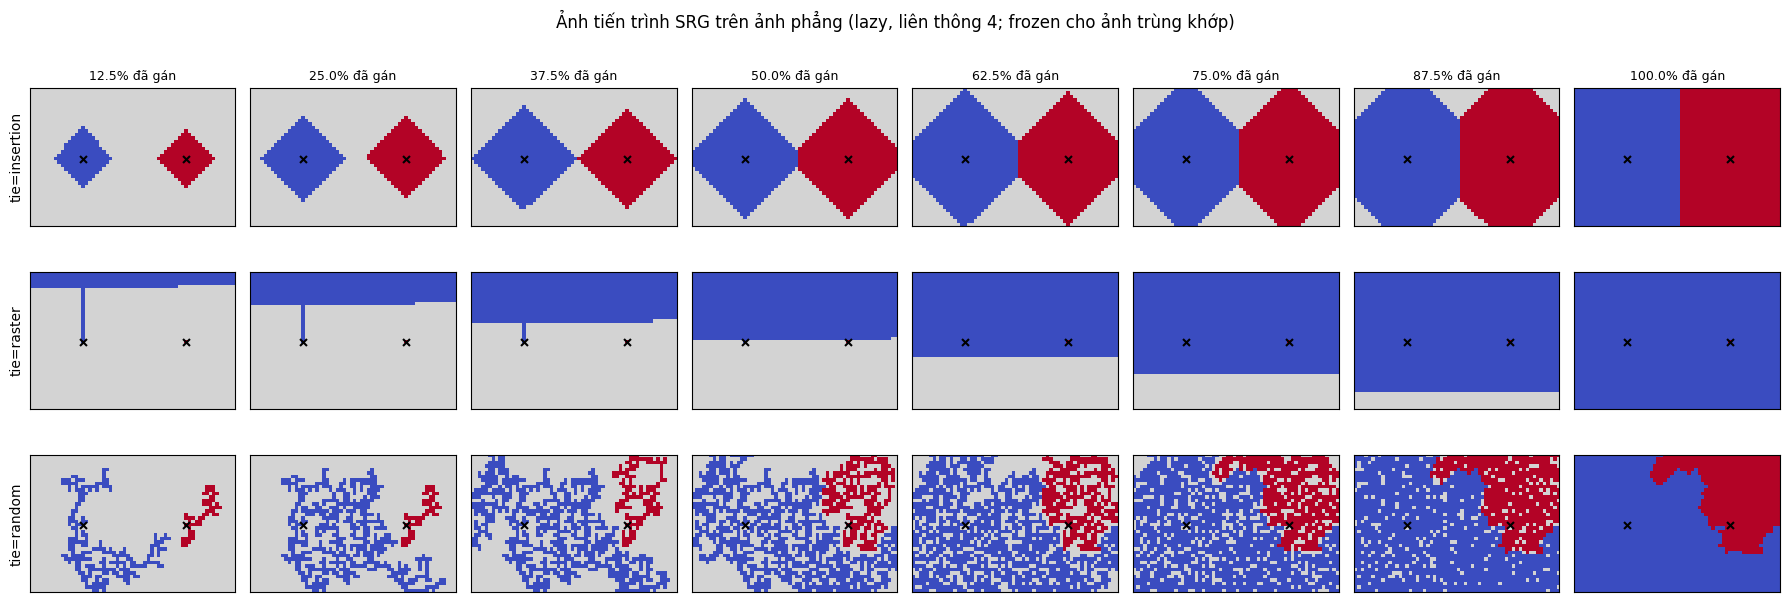

tie=random, liên thông 4, TIE_RANDOM_SEED = 0..9
Diện tích vùng 0: [1746, 950, 952, 1410, 561, 1590, 1041, 1708, 1790, 1]
Nhỏ nhất 1, lớn nhất 1790 trên 2400 pixel


In [11]:
CAO, RONG = 40, 60
GIA_TRI_PHANG = 128.0
anh_phang = np.full((CAO, RONG), GIA_TRI_PHANG)
hat_giong_phang = [(20, 15), (20, 45)]          
CAC_LUAT_HOA = ("insertion", "raster", "random")
CAC_CHE_DO_CU = ("lazy", "frozen")
CAC_LIEN_THONG = (4, 8)

print(f"Cấu hình: ảnh {CAO}x{RONG}, mọi pixel = {GIA_TRI_PHANG}, hạt giống = {hat_giong_phang}, "
      f"TIE_RANDOM_SEED = {TIE_RANDOM_SEED}")


def khoang_cach_toi_hat(hat, lien_thong):
    """Số bước ngắn nhất tới hạt trên ảnh không vật cản: 4 -> |dr|+|dc|, 8 -> max(|dr|,|dc|)."""
    hang, cot = np.indices((CAO, RONG))
    dr, dc = np.abs(hang - hat[0]), np.abs(cot - hat[1])
    return dr + dc if lien_thong == 4 else np.maximum(dr, dc)


def mo_ta_hinh_dang(nhan, bien, lien_thong):
    """Các số đo mô tả hình dạng hai vùng (chỉ dùng numpy)."""
    mo_ta = {}
    for i in range(len(hat_giong_phang)):
        hang, cot = np.nonzero(nhan == i)
        mo_ta[f"S{i}"] = hang.size
        mo_ta[f"hop{i}"] = f"r{hang.min()}-{hang.max()},c{cot.min()}-{cot.max()}"
    cot_chuyen = [np.argmax(h == 1) if (np.diff(h) >= 0).all() and h[-1] == 1 else -1 for h in nhan]
    mo_ta["chia_doc_tai_cot"] = cot_chuyen[0] if len(set(cot_chuyen)) == 1 and cot_chuyen[0] > 0 else None
    d0 = khoang_cach_toi_hat(hat_giong_phang[0], lien_thong)
    d1 = khoang_cach_toi_hat(hat_giong_phang[1], lien_thong)
    ro_rang = d0 != d1
    gan_nhat = (d1 < d0).astype(np.int32)
    mo_ta["khop_hat_gan_nhat_%"] = 100 * (nhan[ro_rang] == gan_nhat[ro_rang]).mean()
    mo_ta["so_pixel_bien"] = int(bien.sum())
    return mo_ta

ket_qua_b5 = {}
print(f"\n{'cấu hình':<24}{'S0':>6}{'S1':>6}  {'hộp bao vùng 0':<18}{'hộp bao vùng 1':<18}"
      f"{'chia dọc':>9}{'khớp gần nhất %':>17}{'biên':>6}{'t (ms)':>8}")
for lien_thong in CAC_LIEN_THONG:
    for luat in CAC_LUAT_HOA:
        for che_do in CAC_CHE_DO_CU:
            t0 = time.perf_counter()
            nhan, bien = srg(anh_phang, hat_giong_phang, connectivity=lien_thong, stale=che_do, tie=luat)
            t_ms = 1000 * (time.perf_counter() - t0)
            cau_hinh = f"{che_do}/{luat}/{lien_thong}"
            assert (nhan >= 0).all(), f"{cau_hinh}: còn pixel chưa gán"
            assert set(np.unique(nhan)) == {0, 1}, f"{cau_hinh}: số vùng khác 2"
            nhan_lai, _ = srg(anh_phang, hat_giong_phang, connectivity=lien_thong, stale=che_do, tie=luat)
            assert (nhan_lai == nhan).all(), f"{cau_hinh}: chạy lại cho kết quả khác"
            ket_qua_b5[(lien_thong, luat, che_do)] = nhan
            m = mo_ta_hinh_dang(nhan, bien, lien_thong)
            print(f"{cau_hinh:<24}{m['S0']:>6}{m['S1']:>6}  {m['hop0']:<18}{m['hop1']:<18}"
                  f"{str(m['chia_doc_tai_cot']):>9}{m['khop_hat_gan_nhat_%']:>17.1f}{m['so_pixel_bien']:>6}{t_ms:>8.1f}")

for lien_thong in CAC_LIEN_THONG:
    for luat in CAC_LUAT_HOA:
        so_khac = int((ket_qua_b5[(lien_thong, luat, "lazy")] != ket_qua_b5[(lien_thong, luat, "frozen")]).sum())
        print(f"liên thông {lien_thong}, tie={luat:<9}: số pixel khác nhau lazy vs frozen = {so_khac}")

for a, b in (("insertion", "raster"), ("insertion", "random"), ("raster", "random")):
    so_khac = int((ket_qua_b5[(4, a, "lazy")] != ket_qua_b5[(4, b, "lazy")]).sum())
    print(f"{a} vs {b}: {so_khac} pixel khác nhau ({100 * so_khac / anh_phang.size:.1f}%)")

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for hang_hinh, lien_thong in enumerate(CAC_LIEN_THONG):
    for cot_hinh, luat in enumerate(CAC_LUAT_HOA):
        ax = axes[hang_hinh, cot_hinh]
        ax.imshow(ket_qua_b5[(lien_thong, luat, "lazy")], cmap="coolwarm", vmin=0, vmax=1)
        for r, c in hat_giong_phang:
            ax.scatter(c, r, marker="x", s=60, c="black")
        ax.set_title(f"tie={luat}, liên thông {lien_thong}")
        ax.axis("off")
fig.suptitle("B5 – Ảnh phẳng, 2 hạt giống (xanh = vùng 0, đỏ = vùng 1); lazy và frozen trùng nhau")
plt.tight_layout()
plt.show()
print("ĐẠT: 12 cấu hình đều phủ hết ảnh, đúng 2 vùng, chạy lại cho cùng kết quả.")

SO_ANH_TIEN_TRINH = 8
anh_tien_trinh = {}
for luat in CAC_LUAT_HOA:
    for che_do in CAC_CHE_DO_CU:
        cac_anh = srg_step_frames(anh_phang, hat_giong_phang, n_frames=SO_ANH_TIEN_TRINH,
                                  connectivity=4, stale=che_do, tie=luat)
        assert len(cac_anh) == SO_ANH_TIEN_TRINH
        assert (cac_anh[-1] >= 0).all(), f"{che_do}/{luat}: ảnh cuối còn pixel chưa gán"
        assert (cac_anh[-1] == ket_qua_b5[(4, luat, che_do)]).all(), "ảnh cuối khác kết quả srg"
        anh_tien_trinh[(luat, che_do)] = cac_anh

print(f"{'tie':<10}" + "".join(f"{f'mốc {k}':>14}" for k in range(1, SO_ANH_TIEN_TRINH + 1)))
for luat in CAC_LUAT_HOA:
    trung = all((a == b).all() for a, b in zip(anh_tien_trinh[(luat, "lazy")], anh_tien_trinh[(luat, "frozen")]))
    dong = "".join(f"{f'{(f == 0).sum()}/{(f == 1).sum()}':>14}" for f in anh_tien_trinh[(luat, "lazy")])
    print(f"{luat:<10}{dong}   lazy == frozen ở cả 8 mốc: {trung}")
print("(mỗi ô: số pixel vùng 0 / vùng 1 tại mốc đó)")

fig, axes = plt.subplots(len(CAC_LUAT_HOA), SO_ANH_TIEN_TRINH, figsize=(18, 6.5))
for hang_hinh, luat in enumerate(CAC_LUAT_HOA):
    for k, (ax, anh) in enumerate(zip(axes[hang_hinh], anh_tien_trinh[(luat, "lazy")]), start=1):
        ax.imshow(np.ma.masked_less(anh, 0), cmap="coolwarm", vmin=0, vmax=1)
        ax.set_facecolor("lightgray")          
        for r, c in hat_giong_phang:
            ax.scatter(c, r, marker="x", s=25, c="black")
        ax.set_xticks([]); ax.set_yticks([])
        if hang_hinh == 0:
            ax.set_title(f"{100 * (anh >= 0).mean():.1f}% đã gán", fontsize=9)
        if k == 1:
            ax.set_ylabel(f"tie={luat}", fontsize=10)
fig.suptitle("Ảnh tiến trình SRG trên ảnh phẳng (lazy, liên thông 4; frozen cho ảnh trùng khớp)")
plt.tight_layout()
plt.show()

HAT_NGAU_NHIEN_GOC = TIE_RANDOM_SEED
dien_tich_vung_0 = []
for hat_nn in range(10):
    TIE_RANDOM_SEED = hat_nn                   
    nhan, _ = srg(anh_phang, hat_giong_phang, connectivity=4, stale="lazy", tie="random")
    assert (nhan >= 0).all() and set(np.unique(nhan)) == {0, 1}
    dien_tich_vung_0.append(int((nhan == 0).sum()))
TIE_RANDOM_SEED = HAT_NGAU_NHIEN_GOC           
print("tie=random, liên thông 4, TIE_RANDOM_SEED = 0..9")
print("Diện tích vùng 0:", dien_tich_vung_0)
print(f"Nhỏ nhất {min(dien_tich_vung_0)}, lớn nhất {max(dien_tich_vung_0)} trên {anh_phang.size} pixel")

**Nhận xét kiểm chứng B5**

- **Kết quả thực tế:** Cả 12 cấu hình đều gán đủ 2.400 pixel vào đúng hai vùng và cho cùng bản đồ nhãn khi chạy lại. Với liên thông 4 và `TIE_RANDOM_SEED = 0`:
  - `insertion`: Hai vùng ban đầu lan theo dạng hình thoi. Kết quả cuối chia dọc tại cột 31, với 1.240 pixel ở vùng 0 và 1.160 ở vùng 1. Các pixel gần một hạt hơn hẳn đều được gán đúng hạt gần nhất. Khi hai vùng có cùng δ tại một pixel, vùng có khóa hạt nhỏ hơn được chọn. Vì vậy, ở chế độ `insertion`, cột 30 cách đều hai hạt thuộc vùng 0.
  - `raster`: Vùng 0 lan lên hàng trên rồi chiếm gần hết ảnh. Vùng 1 chỉ còn pixel hạt giống, với diện tích hai vùng là 2.399 và 1 pixel.
  - `random`: Đường biên phụ thuộc vào khóa ngẫu nhiên. Vùng 0 có 1.746 pixel và vùng 1 có 654 pixel. Khi đổi seed ngẫu nhiên từ 0 đến 9, diện tích vùng 0 dao động từ 1 đến 1.790 pixel.
- **Đạt:** `lazy` và `frozen` cho cùng bản đồ nhãn ở cả 6 cặp cấu hình. Với liên thông 4, hai chế độ cũng trùng nhau tại cả 8 mốc tiến trình cho từng quy tắc phá hòa. Trên ảnh phẳng, mọi δ đều bằng 0 nên cách phá hòa quyết định thứ tự lan và hình dạng vùng. Sự khác biệt giữa `lazy` và `frozen` sẽ được kiểm tra trên ảnh chuyển màu ở Vòng 3.

## Thí nghiệm - A1: Harris-Laplace so với Harris cổ điển

Tự chọn dữ liệu, trục quét, số đo và kết luận. Theo mục 5.1, mỗi cặp cần bằng chứng khác biệt, quét tham số có ý nghĩa và giải thích cơ chế. Nếu thực tế dùng AI hỗ trợ cell thí nghiệm, ghi prompt nguyên văn ngay phía trên cell đó.

### Thiết kế và bằng chứng khác biệt

Nêu ảnh nào, vì sao chọn, giữ cố định điều kiện gì và đo đại lượng nào. Trình bày kết quả của hai phương pháp.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

**Nhận xét từ số liệu đã chạy:**



### Quét tham số

Ghi trục quét, giá trị thử và các điều kiện giữ cố định; trình bày đường cong hoặc điểm chuyển hành vi.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

**Nhận xét từ số liệu đã chạy:**



### Giải thích kết quả

Điền kết quả đo, giải thích đại lượng nào thay đổi, ở bước nào và vì sao. Báo cả trường hợp chưa cải thiện.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

**Nhận xét từ số liệu đã chạy:**



## Thí nghiệm - A2: ANMS so với Top-N của Harris một tỉ lệ

Tự chọn dữ liệu, trục quét, số đo và kết luận. Theo mục 5.1, mỗi cặp cần bằng chứng khác biệt, quét tham số có ý nghĩa và giải thích cơ chế. Nếu thực tế dùng AI hỗ trợ cell thí nghiệm, ghi prompt nguyên văn ngay phía trên cell đó.

### Thiết kế và bằng chứng khác biệt

Nêu ảnh nào, vì sao chọn, giữ cố định điều kiện gì và đo đại lượng nào. Trình bày kết quả của hai phương pháp.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

**Nhận xét từ số liệu đã chạy:**



### Quét tham số

Ghi trục quét, giá trị thử và các điều kiện giữ cố định; trình bày đường cong hoặc điểm chuyển hành vi.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

**Nhận xét từ số liệu đã chạy:**



### Giải thích kết quả

Điền kết quả đo, giải thích đại lượng nào thay đổi, ở bước nào và vì sao. Báo cả trường hợp chưa cải thiện.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

**Nhận xét từ số liệu đã chạy:**



## Thí nghiệm B - SRG so với Region Growing

Sen so sánh hai phương pháp trên cùng ảnh xám `uneven_lighting.jpg` 480 × 640 và cùng hai hạt giống. Hai phép đo bổ sung dùng ảnh tổng hợp để tìm ngưỡng rò rỉ theo tương phản và so sánh độ nhạy với jitter.

Hiệp dùng ảnh dốc có biên thật và các bản thu nhỏ của ảnh thực để đo ảnh hưởng của `lazy`/`frozen` và quy tắc phá hòa. Phần này dùng bộ hạt giống riêng cho từng cấu hình.

### Thiết kế và bằng chứng khác biệt

Nêu ảnh nào, vì sao chọn, giữ cố định điều kiện gì và đo đại lượng nào. Trình bày kết quả của hai phương pháp.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: ChatGPT (OpenAI).
- Mục đích: Hỗ trợ xây dựng cell thí nghiệm so sánh Region Growing và Seeded Region Growing (SRG), sử dụng ảnh và hạt giống đã có trong notebook.
- Prompt nguyên văn: Hướng dẫn xây dựng thí nghiệm so sánh Region Growing và SRG trên cùng một ảnh, giữ cố định hạt giống và điều kiện đầu vào, tính số pixel được phân vùng và số pixel chưa được gán nhãn, đồng thời trực quan hóa kết quả để làm rõ sự khác biệt giữa hai phương pháp.
- Phần đã tự sửa và kiểm tra: Đối chiếu tên hàm, biến ảnh và hạt giống với notebook; kiểm tra kết quả chạy thực tế và hình ảnh đầu ra.

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

=== KẾT QUẢ SO SÁNH ===
Ảnh đầu vào: (480, 640)
Ngưỡng T: 15
Số hạt giống: 2

Region Growing:
Pixel đã gán nhãn: 118553
Pixel chưa gán nhãn: 188647
Số pixel mỗi vùng: {0: 56298, 1: 62255}

SRG:
Pixel đã gán nhãn: 307200
Pixel chưa gán nhãn: 0
Số pixel mỗi vùng: {0: 120309, 1: 186891}
Pixel biên: 1045

Số pixel khác nhãn trên vùng chung: 2


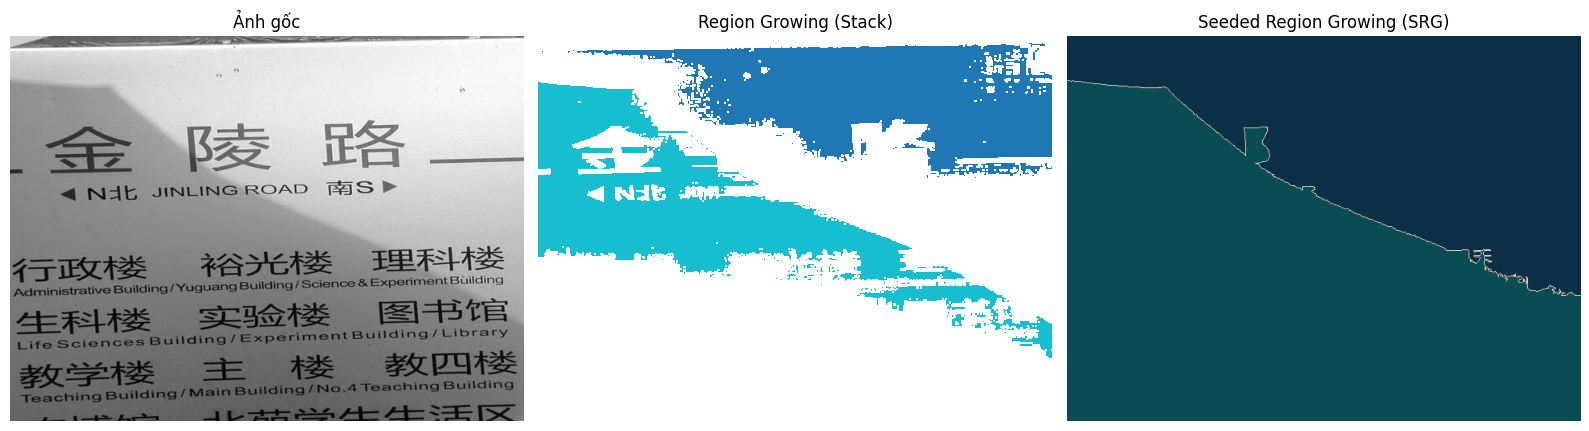

In [12]:
# So sánh Region Growing cổ điển và SRG trên cùng dữ liệu

labels_classic = region_growing_classic(
    test_img,
    test_seeds,
    T=T_test,
    order="stack"
)

labels_srg, boundary_mask = srg(
    test_img,
    test_seeds,
    connectivity=4,
    stale="lazy",
    tie="insertion"
)

# Thống kê số pixel được phân vùng
classic_assigned = np.count_nonzero(labels_classic >= 0)
srg_assigned = np.count_nonzero(labels_srg >= 0)

classic_unassigned = np.count_nonzero(labels_classic < 0)
srg_unassigned = np.count_nonzero(labels_srg < 0)

print("=== KẾT QUẢ SO SÁNH ===")
print("Ảnh đầu vào:", test_img.shape)
print("Ngưỡng T:", T_test)
print("Số hạt giống:", len(test_seeds))

print("\nRegion Growing:")
print("Pixel đã gán nhãn:", classic_assigned)
print("Pixel chưa gán nhãn:", classic_unassigned)
print("Số pixel mỗi vùng:",
      {int(k): int(np.sum(labels_classic == k))
       for k in np.unique(labels_classic) if k >= 0})

print("\nSRG:")
print("Pixel đã gán nhãn:", srg_assigned)
print("Pixel chưa gán nhãn:", srg_unassigned)
print("Số pixel mỗi vùng:",
      {int(k): int(np.sum(labels_srg == k))
       for k in np.unique(labels_srg)})
print("Pixel biên:", np.count_nonzero(boundary_mask))

# So sánh nhãn trên những pixel Region Growing đã phân vùng
common_mask = labels_classic >= 0
different_pixels = np.count_nonzero(
    labels_classic[common_mask] != labels_srg[common_mask]
)

print("\nSố pixel khác nhãn trên vùng chung:", different_pixels)

# Hiển thị kết quả
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(test_img, cmap="gray")
axes[0].set_title("Ảnh gốc")

axes[1].imshow(
    np.ma.masked_less(labels_classic, 0),
    cmap="tab10",
    vmin=0,
    vmax=len(test_seeds) - 1
)
axes[1].set_title("Region Growing (Stack)")

axes[2].imshow(
    labels_srg,
    cmap="tab10",
    vmin=0,
    vmax=len(test_seeds) - 1
)
axes[2].imshow(
    boundary_mask,
    cmap="gray",
    alpha=0.6
)
axes[2].set_title("Seeded Region Growing (SRG)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

**Nhận xét từ số liệu đã chạy:**
Trên cùng ảnh đầu vào và cùng hai hạt giống, Region Growing cổ điển chỉ gán nhãn được 118.553 pixel, còn 188.647 pixel chưa được phân vùng. Ngược lại, SRG gán nhãn toàn bộ 307.200 pixel và xác định 1.045 pixel biên. Kết quả cho thấy SRG có khả năng phân hoạch toàn bộ ảnh tốt hơn trong thí nghiệm này, trong khi Region Growing cổ điển còn để lại nhiều pixel chưa được gán nhãn.

### Quét tham số

Ghi trục quét, giá trị thử và các điều kiện giữ cố định; trình bày đường cong hoặc điểm chuyển hành vi.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: ChatGPT (OpenAI).
- Mục đích: Hỗ trợ xây dựng thí nghiệm quét ngưỡng T cho Region Growing cổ điển, thống kê số vùng, diện tích vùng lớn nhất và trực quan hóa kết quả.
- Prompt nguyên văn: Hãy hỗ trợ xây dựng cell thí nghiệm quét tham số T cho bài toán Region Growing cổ điển. Sử dụng hàm region_growing_classic đã được cài đặt sẵn, ảnh test_img và test_seeds có trong notebook. Với nhiều giá trị T, hãy thống kê số vùng thực tế, số pixel đã gán nhãn, tỷ lệ pixel đã gán nhãn và diện tích vùng lớn nhất. Vẽ biểu đồ thể hiện sự thay đổi của các đại lượng theo T. Không viết lại hoặc chỉnh sửa hàm cài đặt thuật toán.
- Phần đã tự sửa và kiểm tra: Kiểm tra tên biến, phạm vi T, kết quả thống kê và biểu đồ sau khi chạy.

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

In [13]:
# Quét ngưỡng T cho Region Growing cổ điển

T_values = [5, 10, 15, 20, 25, 30, 40, 50, 60]

scan_results = []

for T_value in T_values:
    labels = region_growing_classic(
        test_img,
        test_seeds,
        T=T_value,
        order="stack"
    )

    valid_pixels = labels >= 0
    assigned_count = int(np.count_nonzero(valid_pixels))
    total_pixels = labels.size

    unique_labels, counts = np.unique(
        labels[valid_pixels],
        return_counts=True
    )

    num_regions = len(unique_labels)
    largest_region = int(counts.max()) if len(counts) > 0 else 0
    assigned_ratio = assigned_count / total_pixels * 100

    scan_results.append({
        "T": T_value,
        "regions": num_regions,
        "assigned": assigned_count,
        "ratio": assigned_ratio,
        "largest": largest_region
    })

    print(
        f"T={T_value:2d} | "
        f"Số vùng={num_regions} | "
        f"Pixel đã gán={assigned_count} | "
        f"Tỷ lệ={assigned_ratio:.2f}% | "
        f"Vùng lớn nhất={largest_region}"
    )

print("\nHoàn thành quét tham số.")

T= 5 | Số vùng=2 | Pixel đã gán=24370 | Tỷ lệ=7.93% | Vùng lớn nhất=18010
T=10 | Số vùng=2 | Pixel đã gán=79172 | Tỷ lệ=25.77% | Vùng lớn nhất=39822


T=15 | Số vùng=2 | Pixel đã gán=118553 | Tỷ lệ=38.59% | Vùng lớn nhất=62255


T=20 | Số vùng=2 | Pixel đã gán=176365 | Tỷ lệ=57.41% | Vùng lớn nhất=104588


T=25 | Số vùng=2 | Pixel đã gán=212464 | Tỷ lệ=69.16% | Vùng lớn nhất=128434


T=30 | Số vùng=2 | Pixel đã gán=236324 | Tỷ lệ=76.93% | Vùng lớn nhất=142890


T=40 | Số vùng=2 | Pixel đã gán=254287 | Tỷ lệ=82.78% | Vùng lớn nhất=153724


T=50 | Số vùng=2 | Pixel đã gán=263041 | Tỷ lệ=85.63% | Vùng lớn nhất=156041


T=60 | Số vùng=2 | Pixel đã gán=266007 | Tỷ lệ=86.59% | Vùng lớn nhất=136757

Hoàn thành quét tham số.


**Nhận xét từ số liệu đã chạy:**
Kết quả quét tham số cho thấy khi ngưỡng T tăng từ 5 lên 60, số pixel được gán nhãn tăng từ 24.370 lên 266.007 pixel, tương ứng tỷ lệ bao phủ tăng từ 7,93% lên 86,59%.
Số vùng luôn bằng 2 trong tất cả các lần thử nghiệm, tương ứng với 2 hạt giống ban đầu. Diện tích vùng lớn nhất tăng đáng kể khi T tăng từ 5 đến 50, sau đó giảm ở T = 60. Điều này cho thấy ngưỡng T ảnh hưởng rõ rệt đến khả năng phát triển và sự phân bố pixel giữa các vùng.

### Giải thích kết quả
Điền kết quả đo, giải thích đại lượng nào thay đổi, ở bước nào và vì sao. Báo cả trường hợp chưa cải thiện.

Khi tăng ngưỡng T từ 5 lên 60, số pixel được gán nhãn tăng từ 24.370 lên 266.007 pixel. Nguyên nhân là ngưỡng T càng lớn thì điều kiện chấp nhận pixel càng dễ thỏa mãn, giúp vùng phát triển và tiếp nhận thêm nhiều pixel lân cận.

Số vùng vẫn giữ nguyên là 2 vì thuật toán sử dụng 2 hạt giống ban đầu. Diện tích vùng lớn nhất tăng từ 18.010 pixel tại T = 5 lên 156.041 pixel tại T = 50, nhưng giảm còn 136.757 pixel tại T = 60. Điều này cho thấy khi ngưỡng thay đổi, pixel có thể được phân bố lại giữa hai vùng.

Ở ngưỡng thấp, nhiều pixel chưa được gán nhãn do điều kiện phát triển nghiêm ngặt. Khi tăng ngưỡng, các vùng mở rộng mạnh hơn, nhưng cũng có nguy cơ phát triển vượt khỏi khu vực mong muốn và gây hiện tượng rò rỉ vùng.

Kết luận: Ngưỡng T ảnh hưởng trực tiếp đến số pixel được phân vùng và kích thước các vùng. Vì vậy, cần lựa chọn T phù hợp để cân bằng giữa khả năng bao phủ và hạn chế rò rỉ vùng.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: ChatGPT (OpenAI).
- Mục đích: Hỗ trợ xây dựng biểu đồ trực quan từ kết quả quét tham số T của Region Growing cổ điển.
- Prompt nguyên văn: Dựa trên biến scan_results đã có trong notebook, hãy viết cell Python sử dụng NumPy và Matplotlib để vẽ biểu đồ số vùng, tỷ lệ pixel được gán nhãn và kích thước vùng lớn nhất theo ngưỡng T. Không chạy lại thuật toán phân vùng.
- Phần đã tự sửa và kiểm tra: Đối chiếu tên các trường dữ liệu với cell quét tham số và kiểm tra biểu đồ sau khi chạy.

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

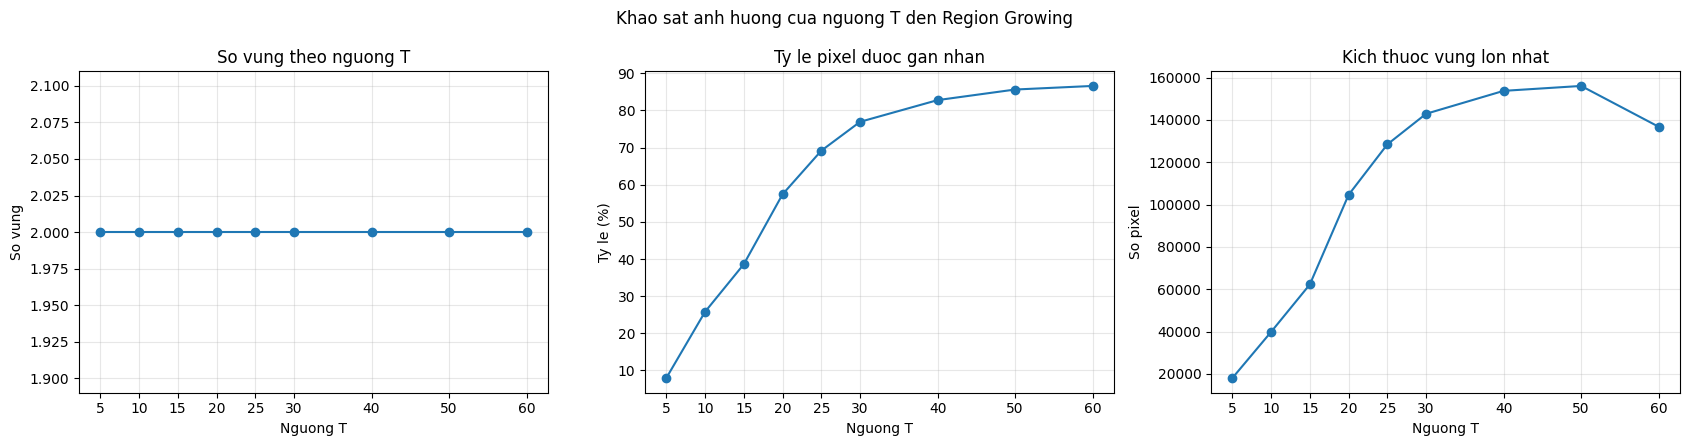

In [14]:
# Biểu đồ kết quả quét tham số T của Region Growing

T_plot = [item["T"] for item in scan_results]
regions_plot = [item["regions"] for item in scan_results]
ratio_plot = [item["ratio"] for item in scan_results]
largest_plot = [item["largest"] for item in scan_results]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# 1. Số vùng theo T
axes[0].plot(T_plot, regions_plot, marker="o")
axes[0].set_title("So vung theo nguong T")
axes[0].set_xlabel("Nguong T")
axes[0].set_ylabel("So vung")
axes[0].set_xticks(T_plot)
axes[0].grid(True, alpha=0.3)

# 2. Ty le pixel duoc gan nhan
axes[1].plot(T_plot, ratio_plot, marker="o")
axes[1].set_title("Ty le pixel duoc gan nhan")
axes[1].set_xlabel("Nguong T")
axes[1].set_ylabel("Ty le (%)")
axes[1].set_xticks(T_plot)
axes[1].grid(True, alpha=0.3)

# 3. Kich thuoc vung lon nhat
axes[2].plot(T_plot, largest_plot, marker="o")
axes[2].set_title("Kich thuoc vung lon nhat")
axes[2].set_xlabel("Nguong T")
axes[2].set_ylabel("So pixel")
axes[2].set_xticks(T_plot)
axes[2].grid(True, alpha=0.3)

plt.suptitle("Khao sat anh huong cua nguong T den Region Growing")
plt.tight_layout()
plt.show()

In [15]:
print("T_plot:", T_plot)
print("regions_plot:", regions_plot)
print("ratio_plot:", ratio_plot)
print("largest_plot:", largest_plot)

T_plot: [5, 10, 15, 20, 25, 30, 40, 50, 60]
regions_plot: [2, 2, 2, 2, 2, 2, 2, 2, 2]
ratio_plot: [7.932942708333333, 25.772135416666668, 38.591471354166664, 57.410481770833336, 69.16145833333334, 76.92838541666667, 82.77571614583333, 85.62532552083333, 86.5908203125]
largest_plot: [18010, 39822, 62255, 104588, 128434, 142890, 153724, 156041, 136757]


**Nhận xét từ số liệu đã chạy:**
Kết quả cho thấy khi tăng ngưỡng T từ 5 lên 60, số pixel được gán nhãn tăng từ 24.370 lên 266.007 pixel, tương ứng tỷ lệ bao phủ tăng từ 7,93% lên 86,59%. Số vùng luôn duy trì ở mức 2 do sử dụng hai hạt giống.

Kích thước vùng lớn nhất tăng từ 18.010 pixel tại T = 5 lên 156.041 pixel tại T = 50, sau đó giảm còn 136.757 pixel tại T = 60. Điều này cho thấy khi tăng T, điều kiện tiếp nhận pixel trở nên ít nghiêm ngặt hơn, khiến các vùng phát triển và có thể làm thay đổi sự phân bố pixel giữa hai vùng.

Đặc biệt, khoảng T = 15 đến T = 25 có sự gia tăng mạnh về số pixel được gán nhãn. Đây là khoảng cần chú ý khi đánh giá nguy cơ vùng phát triển vượt khỏi khu vực mong muốn. T = 60 cũng cho thấy kích thước vùng lớn nhất giảm, chứng tỏ pixel được phân bố lại giữa hai vùng.

Kết luận: Ngưỡng T ảnh hưởng đáng kể đến mức độ bao phủ và kích thước vùng của Region Growing. Cần lựa chọn ngưỡng phù hợp để cân bằng giữa khả năng phân vùng và nguy cơ rò rỉ vùng.


## Thí nghiệm độ nhạy hạt giống (Seed Sensitivity)

Đánh giá mức độ thay đổi kết quả phân vùng khi vị trí các hạt giống bị dịch chuyển. Thực hiện trên cùng ảnh đầu vào và cùng bộ hạt giống ban đầu để so sánh Region Growing cổ điển với Seeded Region Growing (SRG).

**Khai báo cho cell thí nghiệm**

- Công cụ: ChatGPT (OpenAI).
- Mục đích: Hỗ trợ xây dựng thí nghiệm đánh giá độ nhạy hạt giống, so sánh Region Growing cổ điển và SRG.
- Prompt nguyên văn: Hãy hướng dẫn xây dựng thí nghiệm sử dụng hàm seed_sensitivity có sẵn để so sánh độ nhạy hạt giống của Region Growing cổ điển và SRG trên cùng ảnh, cùng bộ seed ban đầu. Tạo bản đồ độ nhạy và biểu diễn kết quả bằng hình ảnh.
- Phần đã tự sửa và kiểm tra: Đối chiếu cách gọi hai thuật toán với chữ ký hàm đã được nhóm cài đặt.

In [16]:
# Hàm trung gian cho Region Growing cổ điển
def run_classic_for_sensitivity(img, seeds):
    return region_growing_classic(
        img,
        seeds,
        T=T_test,
        order="stack"
    )


# Hàm trung gian cho SRG
def run_srg_for_sensitivity(img, seeds):
    labels, boundary_mask = srg(
        img,
        seeds,
        connectivity=4,
        stale="lazy",
        tie="insertion"
    )
    return labels


# Tính bản đồ độ nhạy cho hai phương pháp
sensitivity_classic = seed_sensitivity(
    test_img,
    test_seeds,
    run_classic_for_sensitivity,
    n_trials=20,
    jitter=3
)

sensitivity_srg = seed_sensitivity(
    test_img,
    test_seeds,
    run_srg_for_sensitivity,
    n_trials=20,
    jitter=3
)

print("Kích thước bản đồ Region Growing:", sensitivity_classic.shape)
print("Kích thước bản đồ SRG:", sensitivity_srg.shape)

print("Độ nhạy trung bình Region Growing:",
      np.mean(sensitivity_classic))

print("Độ nhạy trung bình SRG:",
      np.mean(sensitivity_srg))

Kích thước bản đồ Region Growing: (480, 640)
Kích thước bản đồ SRG: (480, 640)
Độ nhạy trung bình Region Growing: 0.014624348
Độ nhạy trung bình SRG: 0.0


In [17]:
# Kiểm tra SRG khi thay đổi vị trí hạt giống

baseline_srg = srg(
    test_img,
    test_seeds,
    connectivity=4,
    stale="lazy",
    tie="insertion"
)[0]

changed_seeds = np.asarray(test_seeds, dtype=np.int32).copy()

# Dịch chuyển hạt giống để kiểm tra
changed_seeds[0, 0] += 3
changed_seeds[1, 0] -= 3

changed_srg = srg(
    test_img,
    changed_seeds.tolist(),
    connectivity=4,
    stale="lazy",
    tie="insertion"
)[0]

print("Hạt giống ban đầu:", test_seeds)
print("Hạt giống sau thay đổi:", changed_seeds.tolist())

print(
    "Số pixel thay đổi nhãn:",
    np.count_nonzero(baseline_srg != changed_srg)
)

Hạt giống ban đầu: [(50, 360), (120, 120)]
Hạt giống sau thay đổi: [[53, 360], [117, 120]]
Số pixel thay đổi nhãn: 0


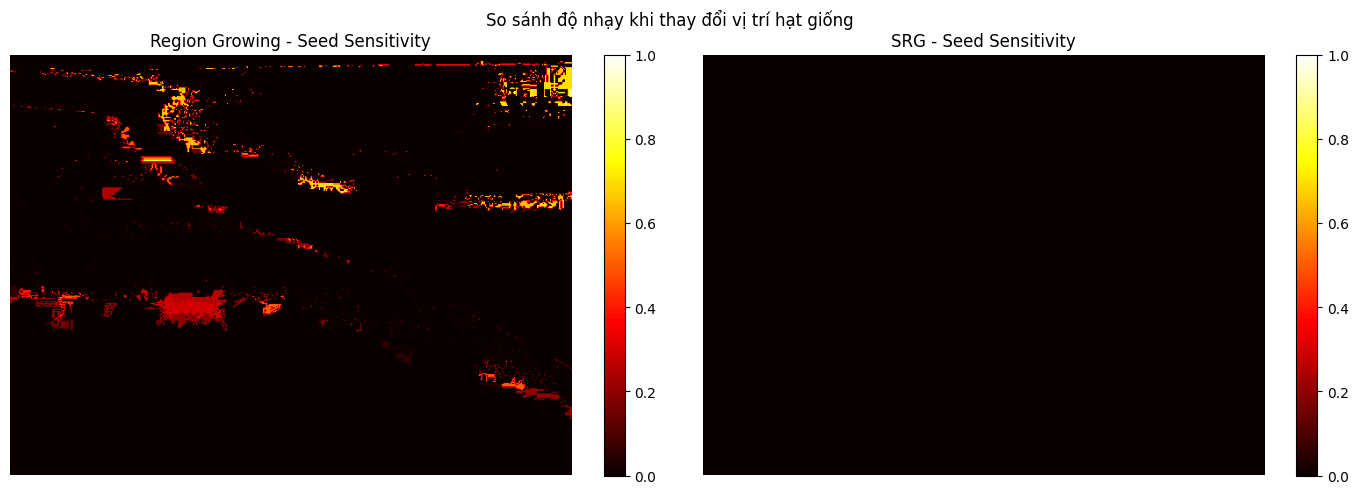

In [18]:
# Hiển thị bản đồ độ nhạy của hai phương pháp

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

im1 = axes[0].imshow(
    sensitivity_classic,
    cmap="hot",
    vmin=0,
    vmax=1
)
axes[0].set_title("Region Growing - Seed Sensitivity")
axes[0].axis("off")
fig.colorbar(im1, ax=axes[0], fraction=0.046)

im2 = axes[1].imshow(
    sensitivity_srg,
    cmap="hot",
    vmin=0,
    vmax=1
)
axes[1].set_title("SRG - Seed Sensitivity")
axes[1].axis("off")
fig.colorbar(im2, ax=axes[1], fraction=0.046)

plt.suptitle("So sánh độ nhạy khi thay đổi vị trí hạt giống")
plt.tight_layout()
plt.show()

In [19]:
for ten, do_nhay_hat_giong in (("Region Growing", sensitivity_classic), ("SRG", sensitivity_srg)):
    so_pixel_doi = np.count_nonzero(do_nhay_hat_giong)
    print(f"{ten}: trung bình {do_nhay_hat_giong.mean():.5f}, lớn nhất {do_nhay_hat_giong.max():.3f}, "
          f"{so_pixel_doi} pixel đổi nhãn ({so_pixel_doi / do_nhay_hat_giong.size:.2%}).")

Region Growing: trung bình 0.01462, lớn nhất 0.900, 11753 pixel đổi nhãn (3.83%).
SRG: trung bình 0.00000, lớn nhất 0.000, 0 pixel đổi nhãn (0.00%).


**Nhận xét kết quả độ nhạy hạt giống**

Thí nghiệm dùng 20 lần thử với jitter tối đa 3 pixel trên cùng ảnh và bộ hạt giống. Một pixel được đếm nếu nó đổi nhãn ít nhất một lần so với kết quả ban đầu. Tỉ lệ trong bảng lấy số pixel đó chia cho toàn bộ số pixel của ảnh.

Hàm `seed_sensitivity` lấy mẫu ngẫu nhiên mỗi lần chạy. Bảng phía trên ghi số đo của lần chạy hiện tại, trên đúng ảnh và bộ hạt giống này.

**Khai báo AI cho cell thí nghiệm**

- Công cụ: ChatGPT (OpenAI).
- Mục đích: Hỗ trợ trực quan hóa kết quả Region Growing khi thay đổi ngưỡng T để quan sát hiện tượng rò rỉ vùng.
- Prompt nguyên văn: "Hãy hỗ trợ xây dựng cell thí nghiệm Python để trực quan hóa kết quả phân vùng Region Growing cổ điển trên cùng một ảnh với nhiều giá trị ngưỡng T, sử dụng hàm region_growing_classic đã có, không viết lại thuật toán cài đặt."
- Phần đã tự sửa và kiểm tra: Kiểm tra các biến đầu vào, đối chiếu kết quả hiển thị với số liệu quét tham số T.

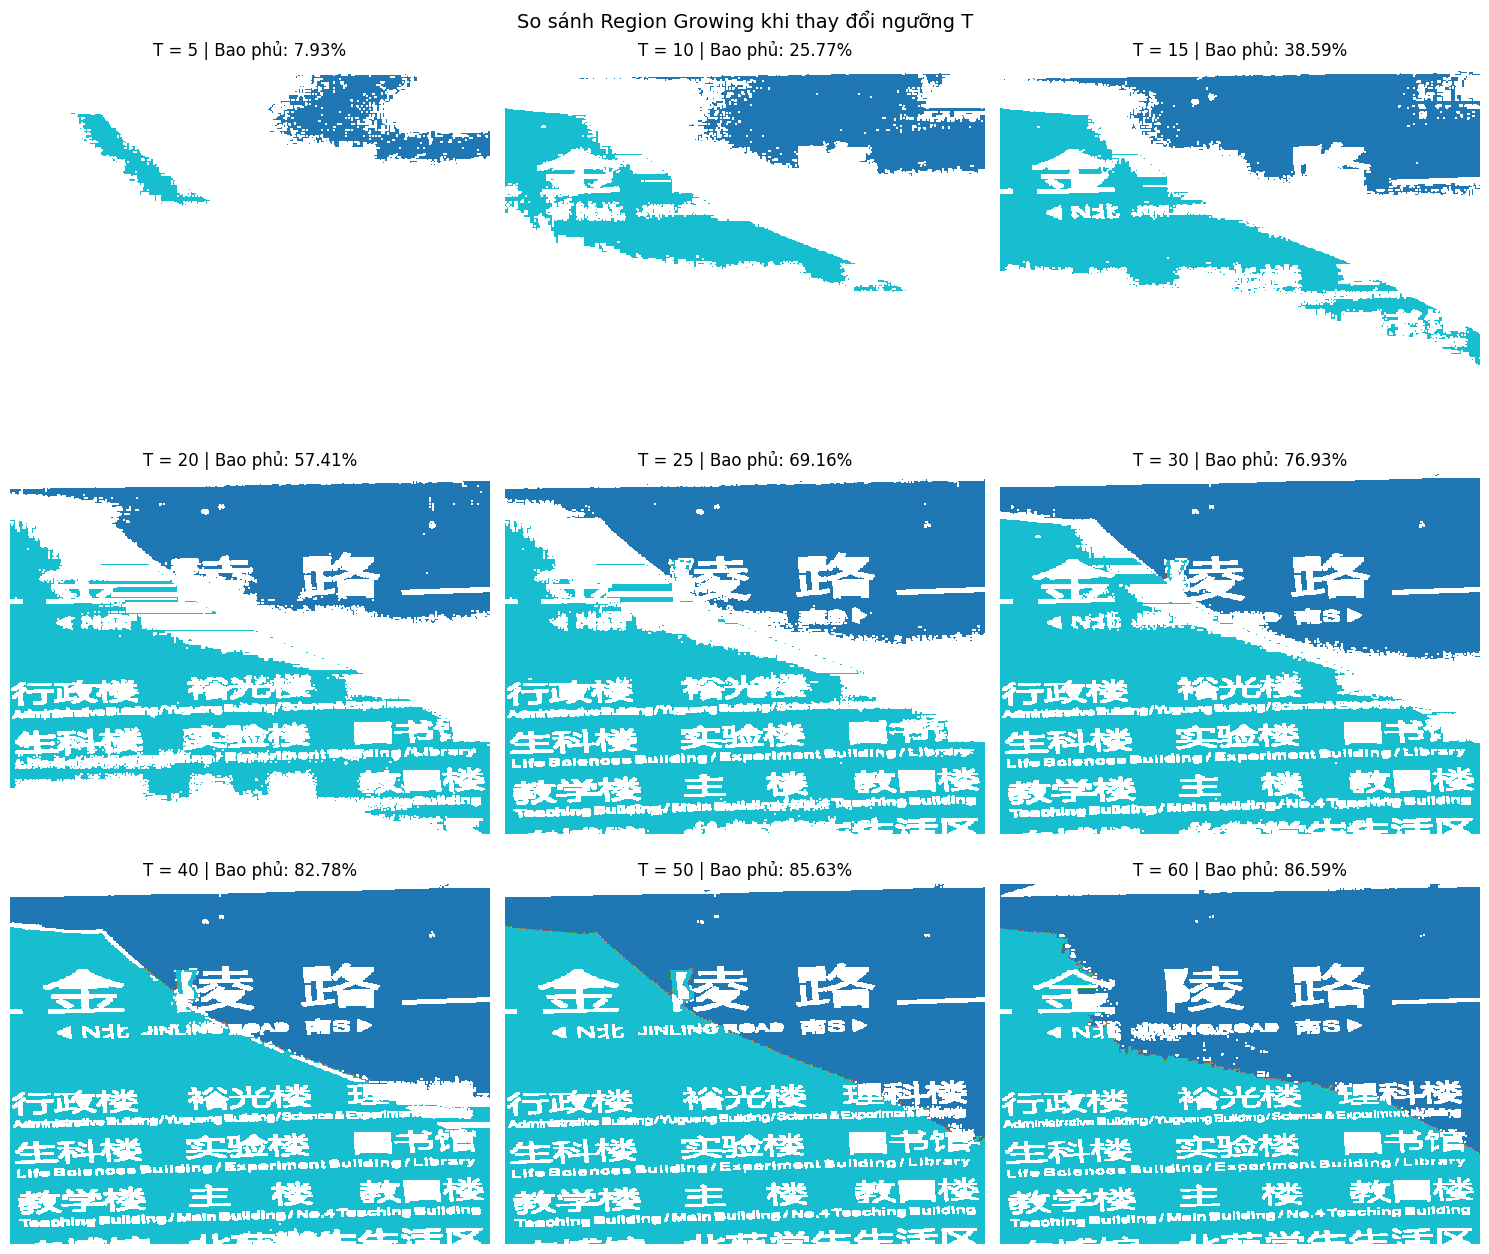

In [20]:
# Trực quan hóa kết quả Region Growing với các ngưỡng T khác nhau

T_visual = [5, 10, 15, 20, 25, 30, 40, 50, 60]

fig, axes = plt.subplots(3, 3, figsize=(15, 13))

for ax, T_value in zip(axes.flat, T_visual):
    labels = region_growing_classic(
        test_img,
        test_seeds,
        T=T_value,
        order="stack"
    )

    display_labels = np.ma.masked_less(labels, 0)

    cmap = plt.get_cmap("tab10").copy()
    cmap.set_bad("white")

    ax.imshow(display_labels, cmap=cmap,
              vmin=0, vmax=max(len(test_seeds) - 1, 1))

    assigned = np.count_nonzero(labels >= 0)
    ratio = assigned / labels.size * 100

    ax.set_title(f"T = {T_value} | Bao phủ: {ratio:.2f}%")
    ax.axis("off")

plt.suptitle(
    "So sánh Region Growing khi thay đổi ngưỡng T",
    fontsize=14
)
plt.tight_layout()
plt.show()

**Nhận xét kết quả trực quan khi thay đổi ngưỡng T**

Qua 9 kết quả trực quan, có thể thấy ngưỡng T ảnh hưởng rõ rệt đến quá trình phát triển của các vùng trong thuật toán Region Growing.

Ở T = 5, tỷ lệ pixel được gán nhãn chỉ đạt 7,93%, cho thấy điều kiện phát triển còn nghiêm ngặt và nhiều pixel chưa được phân vùng. Khi tăng T từ 10 đến 30, các vùng phát triển nhanh hơn, tỷ lệ bao phủ tăng từ 25,77% lên 76,93%.

Tại T = 40 đến 60, tỷ lệ bao phủ tăng chậm hơn, từ 82,78% lên 86,59%. Điều này cho thấy quá trình phát triển vùng dần chậm lại khi các pixel thỏa mãn điều kiện đã được tiếp nhận phần lớn.

Về hiện tượng rò rỉ, các hình cho thấy vùng phân đoạn tiếp tục mở rộng khi tăng T. Tuy nhiên, cần đối chiếu với ảnh gốc để xác định chính xác vùng có lan sang khu vực không mong muốn hay không.

Kết luận: T quá thấp khiến nhiều pixel chưa được gán nhãn, trong khi T cao giúp tăng độ bao phủ nhưng cần kiểm soát nguy cơ phân vùng vượt khỏi khu vực mong muốn. Việc lựa chọn T cần cân bằng giữa độ bao phủ và tính chính xác của vùng phân đoạn.


**Nhận xét hiện tượng phát triển và nguy cơ rò rỉ vùng**

Qua kết quả thực nghiệm, khi tăng ngưỡng T từ 5 lên 60, các vùng phân đoạn mở rộng rõ rệt và tỷ lệ pixel được gán nhãn tăng từ 7,93% lên 86,59%. Ở các mức T thấp, điều kiện tiếp nhận pixel còn nghiêm ngặt nên nhiều khu vực chưa được phân vùng. Khi T tăng, thuật toán có thể tiếp nhận thêm các pixel có cường độ khác biệt lớn hơn so với giá trị trung bình của vùng.

Từ T = 20 đến T = 40, diện tích vùng lớn nhất tăng nhanh, cho thấy khả năng phát triển của vùng được cải thiện. Tuy nhiên, tại T = 60, kích thước vùng lớn nhất giảm so với T = 50, phản ánh sự thay đổi trong phân bố pixel giữa hai vùng.

Kết quả cho thấy việc lựa chọn ngưỡng T cần được cân nhắc giữa khả năng bao phủ ảnh và việc duy trì ranh giới phân vùng. Ngưỡng quá lớn có thể làm tăng nguy cơ vùng phát triển sang khu vực không mong muốn. Tuy nhiên, cần đối chiếu trực tiếp với ảnh gốc để xác định chính xác thời điểm xảy ra hiện tượng rò rỉ vùng.


Nhiễu σ = 4.0, vật 40x40, hạt giống [(40, 40)], order = stack
   C |  T phủ ≥ 99% vật | T rò rỉ đầu tiên |  T* rò rỉ > 1% |  C − T* | rò rỉ tại T*
  20 |               11 |               12 |             17 |       3 |         1.1%
  40 |               11 |               32 |             37 |       3 |         1.8%
  60 |               11 |               52 |             57 |       3 |        99.8%
  80 |               11 |               72 |             76 |       4 |         1.0%


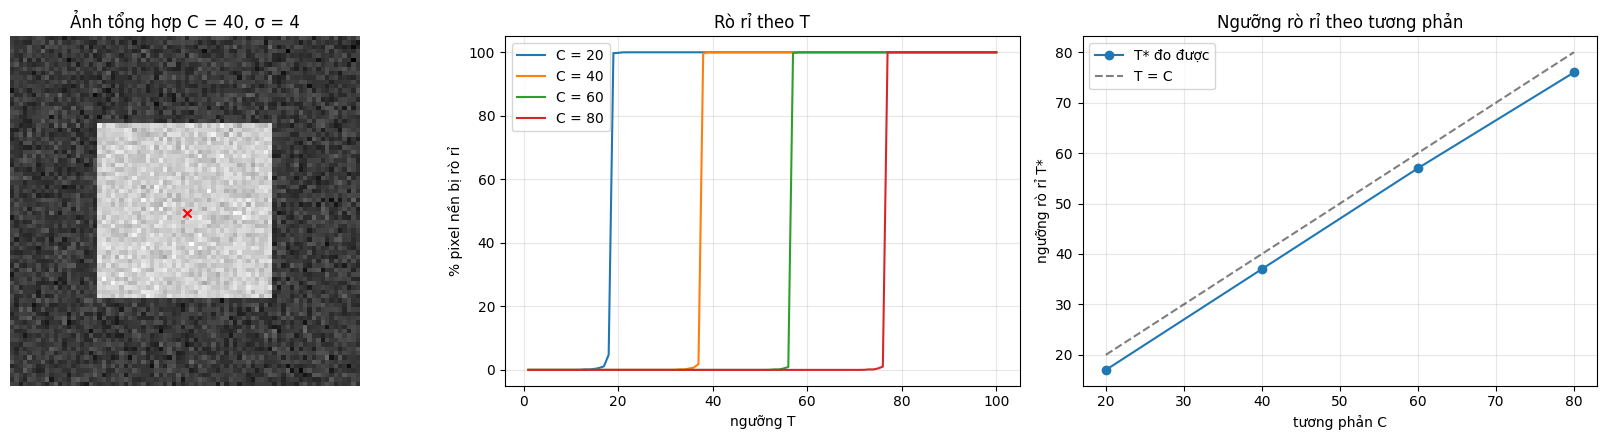

In [21]:
CAO, RONG = 80, 80
NEN = 100.0
DO_NHIEU = 4.0
mat_na_vat = np.zeros((CAO, RONG), dtype=bool)
mat_na_vat[20:60, 20:60] = True
hat_giong_vat = [(40, 40)]


def tao_anh_hai_vung(tuong_phan, do_nhieu=DO_NHIEU, hat_nhieu=0):
    rng = np.random.default_rng(hat_nhieu)
    anh = np.full((CAO, RONG), NEN)
    anh[mat_na_vat] += tuong_phan
    return anh + rng.normal(0.0, do_nhieu, anh.shape)


cac_tuong_phan = [20, 40, 60, 80]
cac_T = np.arange(1, 101)
ti_le_ro_ri = {}
ti_le_phu_vat = {}
T_ro_ri = {}

for C in cac_tuong_phan:
    anh = tao_anh_hai_vung(C)
    ro_ri, phu_vat = [], []
    for T in cac_T:
        nhan = region_growing_classic(anh, hat_giong_vat, T=float(T), order="stack")
        vung = nhan == 0
        ro_ri.append(np.sum(vung & ~mat_na_vat) / np.sum(~mat_na_vat))
        phu_vat.append(np.sum(vung & mat_na_vat) / np.sum(mat_na_vat))
    ti_le_ro_ri[C] = np.array(ro_ri)
    ti_le_phu_vat[C] = np.array(phu_vat)
    vuot = cac_T[ti_le_ro_ri[C] > 0.01]
    T_ro_ri[C] = int(vuot[0]) if len(vuot) else None

print(f"Nhiễu σ = {DO_NHIEU}, vật 40x40, hạt giống {hat_giong_vat}, order = stack")
print(f"{'C':>4} | {'T phủ ≥ 99% vật':>16} | {'T rò rỉ đầu tiên':>16} | {'T* rò rỉ > 1%':>14} | "
      f"{'C − T*':>7} | {'rò rỉ tại T*':>12}")
for C in cac_tuong_phan:
    du_vat = cac_T[ti_le_phu_vat[C] >= 0.99]
    T_du = int(du_vat[0]) if len(du_vat) else None
    co_ro = cac_T[ti_le_ro_ri[C] > 0]
    T_dau = int(co_ro[0]) if len(co_ro) else None
    t = T_ro_ri[C]
    tai_t = ti_le_ro_ri[C][t - 1] if t else float("nan")
    print(f"{C:4d} | {str(T_du):>16} | {str(T_dau):>16} | {str(t):>14} | {str(C - t) if t else '-':>7} | {tai_t:12.1%}")

hinh, truc = plt.subplots(1, 3, figsize=(17, 4.5))
truc[0].imshow(tao_anh_hai_vung(40), cmap="gray")
truc[0].scatter([c for _, c in hat_giong_vat], [r for r, _ in hat_giong_vat], c="red", marker="x")
truc[0].set_title("Ảnh tổng hợp C = 40, σ = 4"); truc[0].axis("off")
for C in cac_tuong_phan:
    truc[1].plot(cac_T, 100 * ti_le_ro_ri[C], label=f"C = {C}")
truc[1].set_xlabel("ngưỡng T"); truc[1].set_ylabel("% pixel nền bị rò rỉ")
truc[1].grid(alpha=0.3); truc[1].legend(); truc[1].set_title("Rò rỉ theo T")
co_T = [C for C in cac_tuong_phan if T_ro_ri[C] is not None]
truc[2].plot(co_T, [T_ro_ri[C] for C in co_T], "o-", label="T* đo được")
truc[2].plot(cac_tuong_phan, cac_tuong_phan, "k--", alpha=0.5, label="T = C")
truc[2].set_xlabel("tương phản C"); truc[2].set_ylabel("ngưỡng rò rỉ T*")
truc[2].grid(alpha=0.3); truc[2].legend(); truc[2].set_title("Ngưỡng rò rỉ theo tương phản")
plt.tight_layout()
plt.show()

Ảnh C = 40, σ = 4.0; hạt giống [(23, 40), (5, 5)]; n_trials = 40; T (RG) = 15
jitter | P ra ngoài |  RG: độ nhạy TB  % px đổi |  SRG: độ nhạy TB  % px đổi
     0 |      0.000 |          0.0000      0.0% |           0.0000      0.0%
     1 |      0.000 |          0.0000      0.0% |           0.0000      0.0%
     2 |      0.000 |          0.0000      0.0% |           0.0000      0.0%
     3 |      0.000 |          0.0000      0.0% |           0.0000      0.0%
     4 |      0.111 |          0.1500    100.0% |           0.0541     77.1%
     5 |      0.182 |          0.2500    100.0% |           0.0541     99.9%
     6 |      0.231 |          0.1750    100.0% |           0.0807    100.0%
     7 |      0.267 |          0.2250    100.0% |           0.1130    100.0%
     8 |      0.294 |          0.2500    100.0% |           0.1104    100.0%
     9 |      0.316 |          0.3249    100.0% |           0.1531    100.0%
    10 |      0.333 |          0.3499    100.0% |           0.1630    100.0

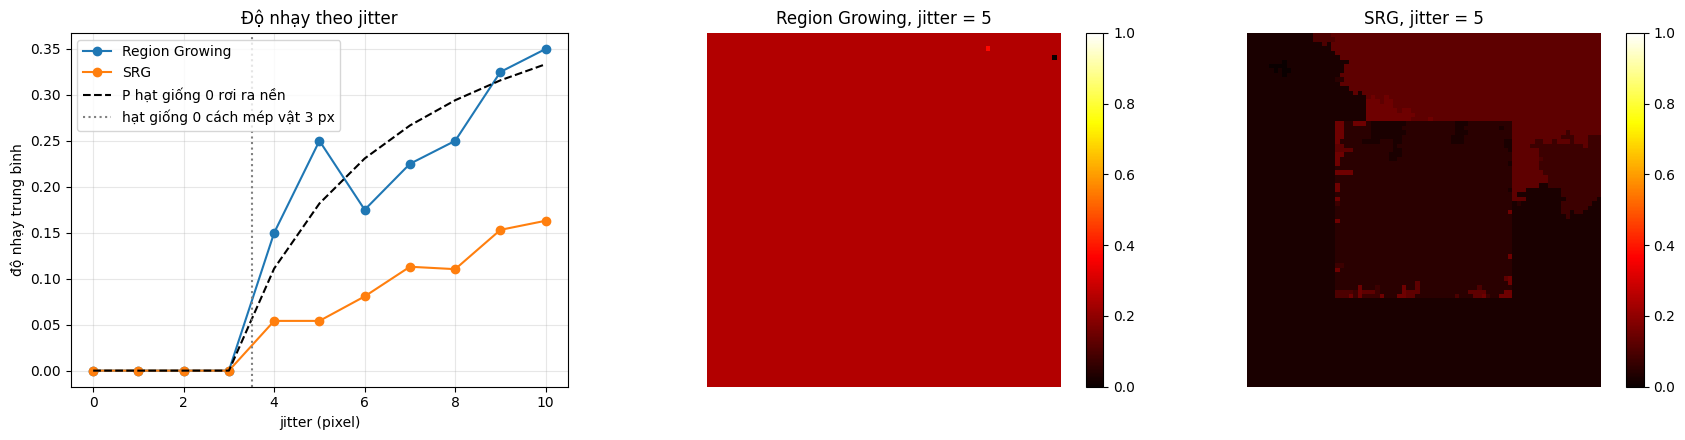

In [22]:
anh_jitter = tao_anh_hai_vung(40)
hat_giong_jitter = [(23, 40), (5, 5)]
T_RG = 15


def chay_rg(anh, hat):
    return region_growing_classic(anh, hat, T=T_RG, order="stack")


def chay_srg(anh, hat):
    return srg(anh, hat, connectivity=4, stale="lazy", tie="insertion")[0]


cac_jitter = list(range(0, 11))
do_nhay = {"Region Growing": [], "SRG": []}
ti_le_doi = {"Region Growing": [], "SRG": []}
ban_do = {}
for j in cac_jitter:
    for ten, ham in (("Region Growing", chay_rg), ("SRG", chay_srg)):
        bd = seed_sensitivity(anh_jitter, hat_giong_jitter, ham, n_trials=40, jitter=j)
        do_nhay[ten].append(float(bd.mean()))
        ti_le_doi[ten].append(float(np.mean(bd > 0)))
        ban_do[(ten, j)] = bd

xac_suat_ra_ngoai = [max(0, j - 3) / (2 * j + 1) for j in cac_jitter]
print(f"Ảnh C = 40, σ = {DO_NHIEU}; hạt giống {hat_giong_jitter}; n_trials = 40; T (RG) = {T_RG}")
print(f"{'jitter':>6} | {'P ra ngoài':>10} | {'RG: độ nhạy TB':>15} {'% px đổi':>9} | {'SRG: độ nhạy TB':>16} {'% px đổi':>9}")
for k, j in enumerate(cac_jitter):
    print(f"{j:6d} | {xac_suat_ra_ngoai[k]:10.3f} | {do_nhay['Region Growing'][k]:15.4f} "
          f"{100 * ti_le_doi['Region Growing'][k]:8.1f}% | "
          f"{do_nhay['SRG'][k]:16.4f} {100 * ti_le_doi['SRG'][k]:8.1f}%")

hinh, truc = plt.subplots(1, 3, figsize=(17, 4.5))
for ten in do_nhay:
    truc[0].plot(cac_jitter, do_nhay[ten], "o-", label=ten)
truc[0].plot(cac_jitter, xac_suat_ra_ngoai, "k--", label="P hạt giống 0 rơi ra nền")
truc[0].axvline(3.5, color="gray", ls=":", label="hạt giống 0 cách mép vật 3 px")
truc[0].set_xlabel("jitter (pixel)"); truc[0].set_ylabel("độ nhạy trung bình")
truc[0].grid(alpha=0.3); truc[0].legend(); truc[0].set_title("Độ nhạy theo jitter")
for k, ten in enumerate(do_nhay, start=1):
    im = truc[k].imshow(ban_do[(ten, 5)], cmap="hot", vmin=0, vmax=1)
    truc[k].set_title(f"{ten}, jitter = 5"); truc[k].axis("off")
    hinh.colorbar(im, ax=truc[k], fraction=0.046)
plt.tight_layout()
plt.show()

## Thí nghiệm - B: SRG lazy/frozen, phá hòa và ảnh tiến trình

Tự chọn dữ liệu, trục quét, số đo và kết luận. Theo mục 5.1, mỗi cặp cần bằng chứng khác biệt, quét tham số có ý nghĩa và giải thích cơ chế. Nếu thực tế dùng AI hỗ trợ cell thí nghiệm, ghi prompt nguyên văn ngay phía trên cell đó.

### Thiết kế và bằng chứng khác biệt

Nêu ảnh nào, vì sao chọn, giữ cố định điều kiện gì và đo đại lượng nào. Trình bày kết quả của hai phương pháp.

Ảnh dốc: 40x120, biên thật ở cột 80, hạt giống = cột 0 và cột 119
Ảnh thật: uneven_lighting.jpg thu về 160x120, hạt giống = [(12, 90), (30, 30)], TIE_RANDOM_SEED = 0


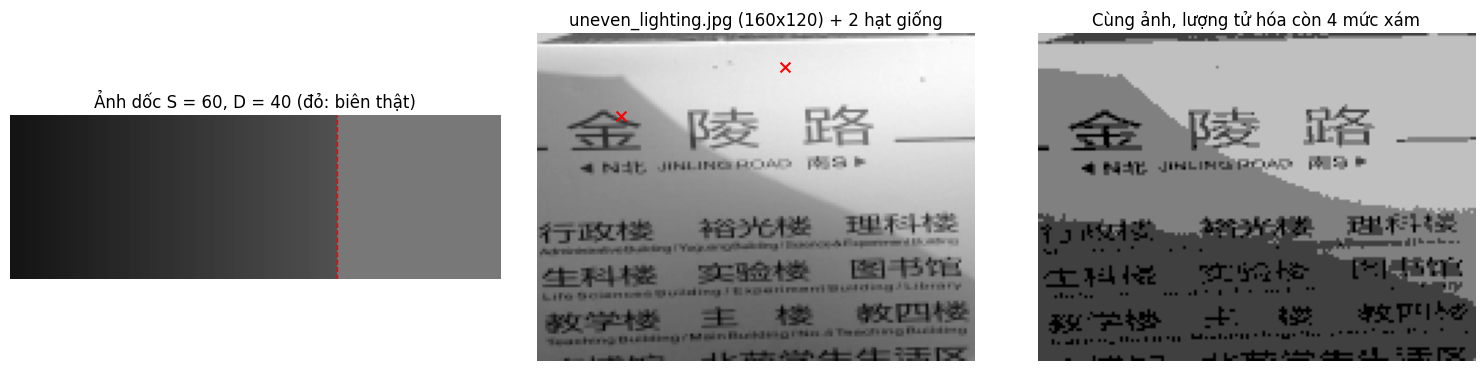

In [23]:
CAC_CHE_DO_CU = ("lazy", "frozen")
CAC_LUAT_HOA = ("insertion", "raster", "random")

CAO_DOC, RONG_DOC, COT_BIEN_THAT = 40, 120, 80
MUC_DAU = 20.0


def tao_anh_doc(do_doc, buoc_bien):
    anh = np.empty((CAO_DOC, RONG_DOC))
    anh[:, :COT_BIEN_THAT] = MUC_DAU + do_doc * np.arange(COT_BIEN_THAT) / (COT_BIEN_THAT - 1)
    anh[:, COT_BIEN_THAT:] = MUC_DAU + do_doc + buoc_bien
    return anh


HAT_DOC = [[(r, 0) for r in range(CAO_DOC)], [(r, RONG_DOC - 1) for r in range(CAO_DOC)]]
NHAN_DUNG_DOC = np.zeros((CAO_DOC, RONG_DOC), dtype=np.int32)
NHAN_DUNG_DOC[:, COT_BIEN_THAT:] = 1


def so_pixel_sai(nhan):
    """Số pixel bị gán khác đáp án đúng của ảnh dốc."""
    return int((nhan != NHAN_DUNG_DOC).sum())


def cot_bien_do_duoc(nhan):
    """Cột đầu tiên thuộc vùng 1 ở hàng giữa (biên thật là cột 80)."""
    return int(np.argmax(nhan[CAO_DOC // 2] == 1))


anh_goc = test_img
anh_that = cv2.resize(anh_goc, (160, 120), interpolation=cv2.INTER_AREA)
HAT_THAT = [(12, 90), (30, 30)]


def luong_tu_hoa(anh, so_muc):
    """Giảm ảnh 8-bit còn so_muc mức xám: càng ít mức, càng nhiều pixel cùng giá trị."""
    buoc = 256 / so_muc
    return np.floor(np.asarray(anh, dtype=float) / buoc) * buoc


def ti_le_lang_gieng_bang_nhau(anh):
    """Tỉ lệ cặp pixel kề nhau (liên thông 4) có cùng giá trị: thước đo mức 'phẳng'."""
    ngang = anh[:, 1:] == anh[:, :-1]
    doc = anh[1:, :] == anh[:-1, :]
    return (ngang.sum() + doc.sum()) / (ngang.size + doc.size)


def so_pixel_khac(nhan_a, nhan_b):
    return int((nhan_a != nhan_b).sum())


def chay_srg_do_gio(anh, hat, **tham_so):
    """Gọi srg và đo thời gian (ms) bằng time.perf_counter."""
    t0 = time.perf_counter()
    nhan, bien = srg(anh, hat, **tham_so)
    return nhan, bien, 1000 * (time.perf_counter() - t0)


print(f"Ảnh dốc: {CAO_DOC}x{RONG_DOC}, biên thật ở cột {COT_BIEN_THAT}, hạt giống = cột 0 và cột {RONG_DOC - 1}")
print(f"Ảnh thật: uneven_lighting.jpg thu về {anh_that.shape[1]}x{anh_that.shape[0]}, "
      f"hạt giống = {HAT_THAT}, TIE_RANDOM_SEED = {TIE_RANDOM_SEED}")

hinh, truc = plt.subplots(1, 3, figsize=(15, 3.6), constrained_layout=True)
truc[0].imshow(tao_anh_doc(60, 40), cmap="gray", vmin=0, vmax=255)
truc[0].axvline(COT_BIEN_THAT - 0.5, color="red", ls="--", lw=1)
truc[0].set_title("Ảnh dốc S = 60, D = 40 (đỏ: biên thật)")
truc[1].imshow(anh_that, cmap="gray")
for hang, cot in HAT_THAT:
    truc[1].scatter(cot, hang, marker="x", s=50, c="red")
truc[1].set_title("uneven_lighting.jpg (160x120) + 2 hạt giống")
truc[2].imshow(luong_tu_hoa(anh_that, 4), cmap="gray", vmin=0, vmax=255)
truc[2].set_title("Cùng ảnh, lượng tử hóa còn 4 mức xám")
for t in truc:
    t.axis("off")
plt.show()

(a) Ảnh dốc S = 60, D = 40, tie = insertion, liên thông 4
stale    pixel sai   % sai  cột biên đo được   t (ms)


lazy             0     0.0                80     26.4
frozen         560    11.7                66     24.6
Biên thật: cột 80. Số pixel khác nhau lazy vs frozen: 560

(b) uneven_lighting.jpg 160x120, hạt giống [(12, 90), (30, 30)], tie = insertion, liên thông 4


lazy     vùng 0 =   7206 px, vùng 1 =  11994 px, pixel biên =  335, t = 153.9 ms


frozen   vùng 0 =   6689 px, vùng 1 =  12511 px, pixel biên =  247, t = 108.3 ms
Số pixel khác nhau lazy vs frozen: 517 (2.7% ảnh)

(c) uneven_lighting.jpg lượng tử hóa 4 mức, lazy, liên thông 4, TIE_RANDOM_SEED = 0
Tỉ lệ cặp pixel kề nhau cùng giá trị: 0.859 (ảnh 8-bit gốc: 0.255)


tie=insertion  vùng 0 =   6924 px, vùng 1 =  12276 px, t = 115.1 ms


tie=raster     vùng 0 =   6778 px, vùng 1 =  12422 px, t = 116.7 ms


tie=random     vùng 0 =   6914 px, vùng 1 =  12286 px, t = 124.2 ms
Số pixel khác nhau insertion vs raster: 232
Số pixel khác nhau insertion vs random: 14
Số pixel khác nhau raster vs random: 222


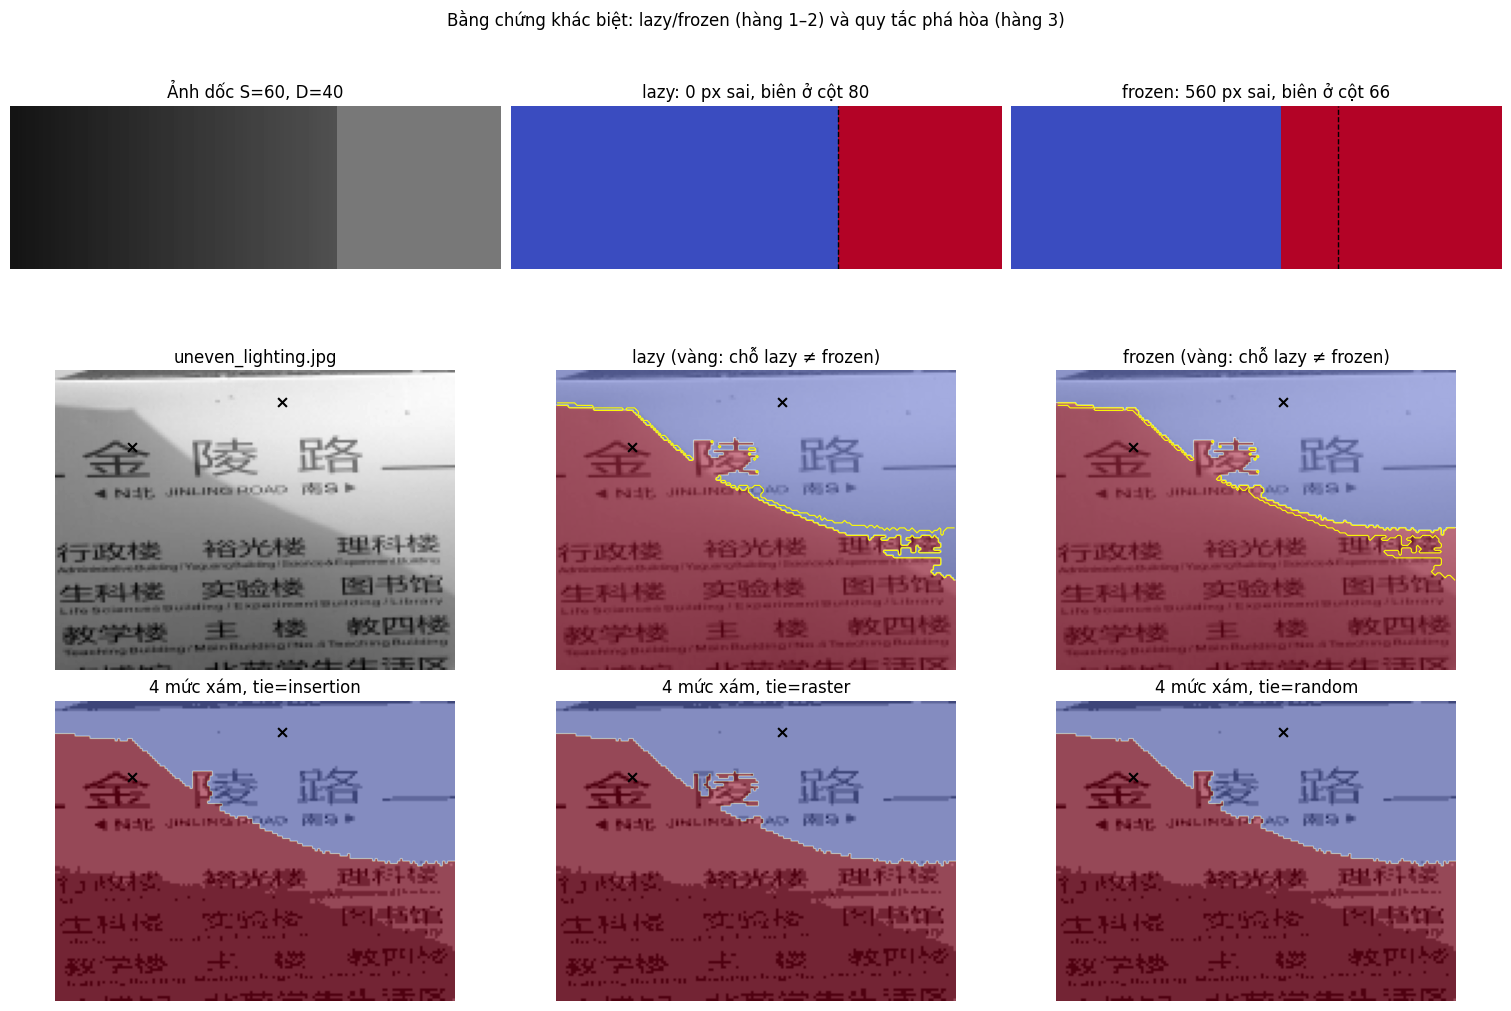

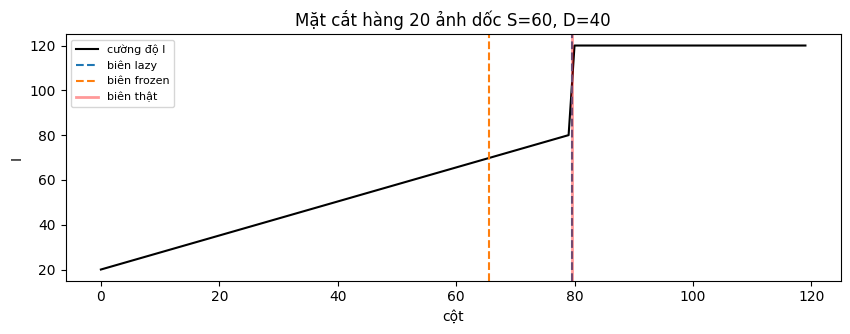

In [24]:
S_MAU, D_MAU = 60, 40
anh_doc_mau = tao_anh_doc(S_MAU, D_MAU)
ket_qua_doc = {}
print(f"(a) Ảnh dốc S = {S_MAU}, D = {D_MAU}, tie = insertion, liên thông 4")
print(f"{'stale':<8}{'pixel sai':>10}{'% sai':>8}{'cột biên đo được':>18}{'t (ms)':>9}")
for che_do in CAC_CHE_DO_CU:
    nhan, bien, t_ms = chay_srg_do_gio(anh_doc_mau, HAT_DOC, stale=che_do)
    assert (nhan >= 0).all() and set(np.unique(nhan)) == {0, 1}
    ket_qua_doc[che_do] = nhan
    print(f"{che_do:<8}{so_pixel_sai(nhan):>10}{100 * so_pixel_sai(nhan) / nhan.size:>8.1f}"
          f"{cot_bien_do_duoc(nhan):>18}{t_ms:>9.1f}")
print(f"Biên thật: cột {COT_BIEN_THAT}. Số pixel khác nhau lazy vs frozen: "
      f"{so_pixel_khac(ket_qua_doc['lazy'], ket_qua_doc['frozen'])}")

print(f"\n(b) uneven_lighting.jpg 160x120, hạt giống {HAT_THAT}, tie = insertion, liên thông 4")
ket_qua_that = {}
for che_do in CAC_CHE_DO_CU:
    nhan, bien, t_ms = chay_srg_do_gio(anh_that, HAT_THAT, stale=che_do)
    assert (nhan >= 0).all()
    ket_qua_that[che_do] = nhan
    print(f"{che_do:<8} vùng 0 = {(nhan == 0).sum():>6} px, vùng 1 = {(nhan == 1).sum():>6} px, "
          f"pixel biên = {bien.sum():>4}, t = {t_ms:.1f} ms")
khac_that = ket_qua_that["lazy"] != ket_qua_that["frozen"]
print(f"Số pixel khác nhau lazy vs frozen: {khac_that.sum()} ({100 * khac_that.mean():.1f}% ảnh)")

SO_MUC_MAU = 4
anh_4_muc = luong_tu_hoa(anh_that, SO_MUC_MAU)
print(f"\n(c) uneven_lighting.jpg lượng tử hóa {SO_MUC_MAU} mức, lazy, liên thông 4, "
      f"TIE_RANDOM_SEED = {TIE_RANDOM_SEED}")
print(f"Tỉ lệ cặp pixel kề nhau cùng giá trị: {ti_le_lang_gieng_bang_nhau(anh_4_muc):.3f} "
      f"(ảnh 8-bit gốc: {ti_le_lang_gieng_bang_nhau(anh_that):.3f})")
ket_qua_hoa = {}
for luat in CAC_LUAT_HOA:
    nhan, _, t_ms = chay_srg_do_gio(anh_4_muc, HAT_THAT, tie=luat)
    assert (nhan >= 0).all()
    nhan_lai, _ = srg(anh_4_muc, HAT_THAT, tie=luat)
    assert (nhan_lai == nhan).all(), f"tie={luat} không tất định"
    ket_qua_hoa[luat] = nhan
    print(f"tie={luat:<10} vùng 0 = {(nhan == 0).sum():>6} px, vùng 1 = {(nhan == 1).sum():>6} px, t = {t_ms:.1f} ms")
for a, b in (("insertion", "raster"), ("insertion", "random"), ("raster", "random")):
    print(f"Số pixel khác nhau {a} vs {b}: {so_pixel_khac(ket_qua_hoa[a], ket_qua_hoa[b])}")
assert max(so_pixel_khac(ket_qua_hoa[a], ket_qua_hoa[b])
           for a in CAC_LUAT_HOA for b in CAC_LUAT_HOA) > 0, "Chưa tìm được ảnh mà đổi tie làm đổi kết quả"

hinh, truc = plt.subplots(3, 3, figsize=(15, 10), constrained_layout=True)
truc[0, 0].imshow(anh_doc_mau, cmap="gray", vmin=0, vmax=255)
truc[0, 0].set_title(f"Ảnh dốc S={S_MAU}, D={D_MAU}")
for k, che_do in enumerate(CAC_CHE_DO_CU, start=1):
    truc[0, k].imshow(ket_qua_doc[che_do], cmap="coolwarm", vmin=0, vmax=1)
    truc[0, k].axvline(COT_BIEN_THAT - 0.5, color="black", ls="--", lw=1)
    truc[0, k].set_title(f"{che_do}: {so_pixel_sai(ket_qua_doc[che_do])} px sai, "
                         f"biên ở cột {cot_bien_do_duoc(ket_qua_doc[che_do])}")
truc[1, 0].imshow(anh_that, cmap="gray")
truc[1, 0].set_title("uneven_lighting.jpg")
for k, che_do in enumerate(CAC_CHE_DO_CU, start=1):
    truc[1, k].imshow(anh_that, cmap="gray")
    truc[1, k].imshow(ket_qua_that[che_do], cmap="coolwarm", alpha=0.45, vmin=0, vmax=1)
    truc[1, k].contour(khac_that, levels=[0.5], colors="yellow", linewidths=0.8)
    truc[1, k].set_title(f"{che_do} (vàng: chỗ lazy ≠ frozen)")
for k, luat in enumerate(CAC_LUAT_HOA):
    truc[2, k].imshow(anh_4_muc, cmap="gray", vmin=0, vmax=255)
    truc[2, k].imshow(ket_qua_hoa[luat], cmap="coolwarm", alpha=0.45, vmin=0, vmax=1)
    truc[2, k].set_title(f"4 mức xám, tie={luat}")
for t in truc.ravel():
    t.axis("off")
for t in truc[1:].ravel():
    for hang, cot in HAT_THAT:
        t.scatter(cot, hang, marker="x", s=40, c="black")
hinh.suptitle("Bằng chứng khác biệt: lazy/frozen (hàng 1–2) và quy tắc phá hòa (hàng 3)")
plt.show()

hinh, truc = plt.subplots(figsize=(10, 3.2))
cot = np.arange(RONG_DOC)
truc.plot(cot, anh_doc_mau[CAO_DOC // 2], "k-", label="cường độ I")
for che_do, mau in zip(CAC_CHE_DO_CU, ("tab:blue", "tab:orange")):
    truc.axvline(cot_bien_do_duoc(ket_qua_doc[che_do]) - 0.5, color=mau, ls="--", label=f"biên {che_do}")
truc.axvline(COT_BIEN_THAT - 0.5, color="red", lw=2, alpha=0.4, label="biên thật")
truc.set_xlabel("cột"); truc.set_ylabel("I"); truc.legend(loc="upper left", fontsize=8)
truc.set_title(f"Mặt cắt hàng {CAO_DOC // 2} ảnh dốc S={S_MAU}, D={D_MAU}")
plt.show()


**Nhận xét từ số liệu đã chạy:**

- Mình chọn ảnh dốc tổng hợp vì biết trước biên thật ở cột 80, nên có thể đếm số pixel gán sai. Ảnh `uneven_lighting.jpg` dùng để xem hai chế độ khác nhau thế nào trên ảnh thật. Khi so sánh, mình giữ nguyên hạt giống, liên thông 4 và quy tắc `insertion`.
- Trên ảnh dốc với S = 60 và D = 40, `lazy` đặt biên đúng ở cột 80. Với `frozen`, vùng bên phải lấn 14 cột, làm biên nằm ở cột 66 và gán sai 560 pixel (11,7%). Trên ảnh thật, hai kết quả khác nhau 517 pixel (2,7%), chủ yếu dọc ranh giới sáng tối.
- Khi giảm ảnh thật xuống 4 mức xám, tỉ lệ cặp pixel kề nhau có cùng giá trị tăng từ 25,5% lên 85,9%. Đổi từ `insertion` sang `raster` làm 232 pixel đổi nhãn. Hai cặp `insertion`–`random` và `raster`–`random` lần lượt khác 14 và 222 pixel. Chạy lại với cùng quy tắc và seed 0 cho kết quả giống lần đầu.

### Quét tham số

Ghi trục quét, giá trị thử và các điều kiện giữ cố định; trình bày đường cong hoặc điểm chuyển hành vi.

Trục 1 – ảnh dốc, tie = insertion, liên thông 4
    S     lazy D=20   frozen D=20     lazy D=40   frozen D=40
    0             0             0             0             0
   20             0             0             0             0
   40            40           800             0             0
   60           640          1080             0           560
   80           840          1200            40           800
  100           920          1280           440           960
  120          1000          1320           640          1080
  140          1040          1360           760          1160
  160          1040          1400           840          1200
D = 20: frozen bắt đầu sai ở S = 25, lazy bắt đầu sai ở S = 40
D = 40: frozen bắt đầu sai ở S = 45, lazy bắt đầu sai ở S = 80

Trục 2 – uneven_lighting.jpg 80x60, lazy, liên thông 4, 12 cặp hạt giống, TIE_RANDOM_SEED = 0
 số mức  cặp kề bằng nhau  cặp hạt bị đổi  % pixel đổi (TB)


    256             0.167          3/12              0.03


     64             0.407          4/12              0.02


     32             0.516          4/12              0.73


     16             0.623          5/12              0.22


      8             0.727          5/12              9.32


      6             0.782          2/12              7.91


      4             0.868          6/12              7.60


      3             0.851          6/12             21.26


      2             0.945          4/12             20.24
(% pixel đổi: với mỗi cặp hạt lấy cặp tie khác nhau nhiều nhất, rồi lấy trung bình 12 cặp)


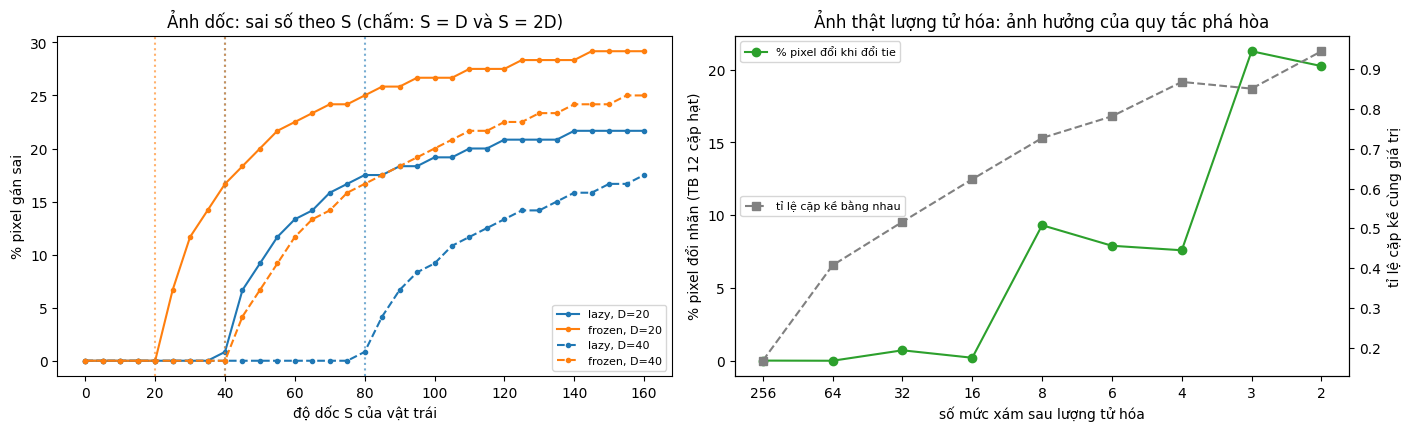

In [25]:
CAC_D = (20, 40)
CAC_S = np.arange(0, 161, 5)
sai_theo_S = {(d, che_do): [] for d in CAC_D for che_do in CAC_CHE_DO_CU}
for d in CAC_D:
    for s in CAC_S:
        anh = tao_anh_doc(s, d)
        for che_do in CAC_CHE_DO_CU:
            nhan, _ = srg(anh, HAT_DOC, stale=che_do)
            sai_theo_S[(d, che_do)].append(so_pixel_sai(nhan))


def S_bat_dau_sai(d, che_do):
    """S nhỏ nhất trong lưới quét mà có pixel bị gán sai."""
    sai = np.array(sai_theo_S[(d, che_do)])
    return int(CAC_S[np.argmax(sai > 0)]) if (sai > 0).any() else None


print("Trục 1 – ảnh dốc, tie = insertion, liên thông 4")
print(f"{'S':>5}" + "".join(f"{f'{c} D={d}':>14}" for d in CAC_D for c in CAC_CHE_DO_CU))
for k, s in enumerate(CAC_S):
    if s % 20 == 0:
        print(f"{s:>5}" + "".join(f"{sai_theo_S[(d, c)][k]:>14}" for d in CAC_D for c in CAC_CHE_DO_CU))
for d in CAC_D:
    print(f"D = {d}: frozen bắt đầu sai ở S = {S_bat_dau_sai(d, 'frozen')}, "
          f"lazy bắt đầu sai ở S = {S_bat_dau_sai(d, 'lazy')}")

anh_nho = cv2.resize(anh_goc, (80, 60), interpolation=cv2.INTER_AREA)
bo_sinh = np.random.default_rng(1)  
CAC_CAP_HAT = []
while len(CAC_CAP_HAT) < 12:
    cap = bo_sinh.integers(0, anh_nho.shape, size=(2, 2))
    if np.abs(cap[0] - cap[1]).sum() >= 20: 
        CAC_CAP_HAT.append([tuple(int(v) for v in p) for p in cap])
CAC_SO_MUC = (256, 64, 32, 16, 8, 6, 4, 3, 2)
ti_le_bang, so_cap_doi, pct_doi = [], [], []
print(f"\nTrục 2 – uneven_lighting.jpg 80x60, lazy, liên thông 4, {len(CAC_CAP_HAT)} cặp hạt giống, "
      f"TIE_RANDOM_SEED = {TIE_RANDOM_SEED}")
print(f"{'số mức':>7}{'cặp kề bằng nhau':>18}{'cặp hạt bị đổi':>16}{'% pixel đổi (TB)':>18}")
for so_muc in CAC_SO_MUC:
    anh_q = luong_tu_hoa(anh_nho, so_muc)
    doi = []
    for hat in CAC_CAP_HAT:
        nhan = {luat: srg(anh_q, hat, tie=luat)[0] for luat in CAC_LUAT_HOA}
        doi.append(max(so_pixel_khac(nhan[a], nhan[b])
                       for a in CAC_LUAT_HOA for b in CAC_LUAT_HOA if a < b))
    ti_le_bang.append(ti_le_lang_gieng_bang_nhau(anh_q))
    so_cap_doi.append(int(np.sum(np.array(doi) > 0)))
    pct_doi.append(100 * np.mean(doi) / anh_q.size)
    print(f"{so_muc:>7}{ti_le_bang[-1]:>18.3f}{so_cap_doi[-1]:>11}/{len(CAC_CAP_HAT)}{pct_doi[-1]:>18.2f}")
print("(% pixel đổi: với mỗi cặp hạt lấy cặp tie khác nhau nhiều nhất, rồi lấy trung bình 12 cặp)")

hinh, truc = plt.subplots(1, 2, figsize=(14, 4.2), constrained_layout=True)
for d, kieu in zip(CAC_D, ("-", "--")):
    for che_do, mau in zip(CAC_CHE_DO_CU, ("tab:blue", "tab:orange")):
        truc[0].plot(CAC_S, 100 * np.array(sai_theo_S[(d, che_do)]) / NHAN_DUNG_DOC.size,
                     kieu, color=mau, marker=".", label=f"{che_do}, D={d}")
    truc[0].axvline(d, color="tab:orange", ls=":", alpha=0.6)
    truc[0].axvline(2 * d, color="tab:blue", ls=":", alpha=0.6)
truc[0].set_xlabel("độ dốc S của vật trái")
truc[0].set_ylabel("% pixel gán sai")
truc[0].set_title("Ảnh dốc: sai số theo S (chấm: S = D và S = 2D)")
truc[0].legend(fontsize=8)
nhan_x = [str(m) for m in CAC_SO_MUC]
truc[1].plot(nhan_x, pct_doi, "o-", color="tab:green", label="% pixel đổi khi đổi tie")
truc[1].set_xlabel("số mức xám sau lượng tử hóa")
truc[1].set_ylabel("% pixel đổi nhãn (TB 12 cặp hạt)")
truc2 = truc[1].twinx()
truc2.plot(nhan_x, ti_le_bang, "s--", color="gray", label="tỉ lệ cặp kề bằng nhau")
truc2.set_ylabel("tỉ lệ cặp kề cùng giá trị")
truc[1].set_title("Ảnh thật lượng tử hóa: ảnh hưởng của quy tắc phá hòa")
truc[1].legend(loc="upper left", fontsize=8); truc2.legend(loc="center left", fontsize=8)
plt.show()

**Nhận xét từ số liệu đã chạy:**

- Khi quét S từ 0 đến 160 (bước 5), mình giữ nguyên hạt giống, liên thông 4 và quy tắc `insertion`. Với D = 20, `frozen` bắt đầu sai ở S = 25, còn `lazy` bắt đầu sai ở S = 40. Với D = 40, hai mốc lần lượt là S = 45 và S = 80. Trên lưới quét, `frozen` bắt đầu sai ngay sau D, còn `lazy` giữ đúng đến gần 2D.
- Với 12 cặp hạt giống cố định trên ảnh thật 80 × 60, tỉ lệ pixel đổi nhãn khi thay quy tắc phá hòa nhìn chung tăng khi giảm số mức xám. Tỉ lệ này là 0,03% ở 256 mức, 9,32% ở 8 mức và 21,26% ở 3 mức, rồi giảm còn 20,24% ở 2 mức. Ngay ở ảnh 256 mức, 3 trong 12 cặp hạt giống đã cho kết quả khác khi đổi quy tắc.

### Giải thích kết quả

Điền kết quả đo, giải thích đại lượng nào thay đổi, ở bước nào và vì sao. Báo cả trường hợp chưa cải thiện.

(a) Ảnh dốc S = 60, D = 40: tham chiếu của từng vùng tại 8 mốc tiến trình
 mốc   lazy: TB vùng 0  TB vùng 1  cột phải nhất v0     frozen: hạt 0  hạt 1  cột phải nhất v0
   1              20.0      120.0                 0              20.0  120.0                 0
   2              20.0      120.0                 0              20.0  120.0                 0
   3              21.5      120.0                 4              20.0  120.0                 4
   4              27.2      120.0                19              20.0  120.0                19
   5              32.9      120.0                34              20.0  120.0                34
   6              38.6      120.0                49              20.0  120.0                49
   7              44.3      120.0                64              20.0  120.0                58
   8              50.0      120.0                79              20.0  120.0                65

Ngưỡng S bắt đầu sai: dự đoán từ công thức (5) vs S đầu tiên có pixel 

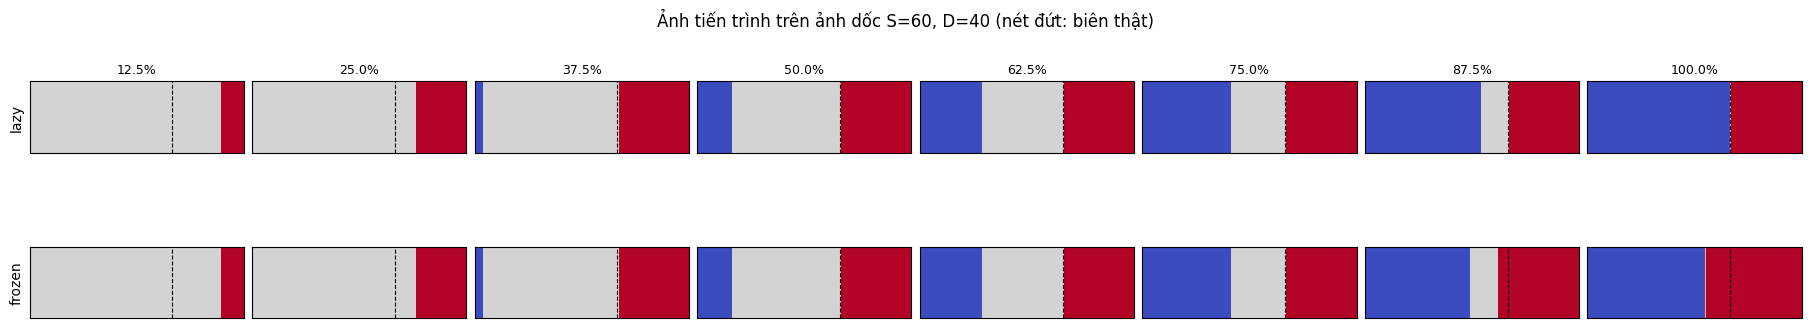


(b) Thời gian srg trên uneven_lighting.jpg, tie = insertion, liên thông 4, lấy min của 3 lần chạy
 kích thước  n pixel  lazy (ms)  frozen (ms)  lazy/frozen  lazy µs/(n·log2 n)


      80x60     4800       38.0         25.9         1.47               0.648


    160x120    19200      151.4        106.2         1.43               0.554


    240x180    43200      342.8        243.2         1.41               0.515


    320x240    76800      612.3        436.5         1.40               0.491


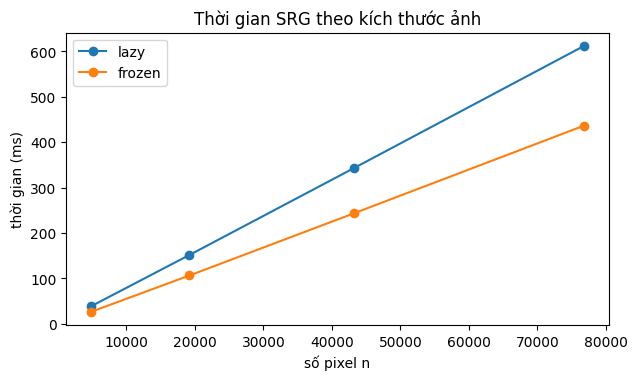

In [26]:
SO_MOC = 8
print(f"(a) Ảnh dốc S = {S_MAU}, D = {D_MAU}: tham chiếu của từng vùng tại {SO_MOC} mốc tiến trình")
print(f"{'mốc':>4}{'':>2}{'lazy: TB vùng 0':>16}{'TB vùng 1':>11}{'cột phải nhất v0':>18}"
      f"{'':>4}{'frozen: hạt 0':>14}{'hạt 1':>7}{'cột phải nhất v0':>18}")
cac_moc = {che_do: srg_step_frames(anh_doc_mau, HAT_DOC, n_frames=SO_MOC, stale=che_do)
           for che_do in CAC_CHE_DO_CU}
tb_vung_0_lazy = []
for k in range(SO_MOC):
    dong = f"{k + 1:>4}{'':>2}"
    for che_do in CAC_CHE_DO_CU:
        f = cac_moc[che_do][k]
        if che_do == "lazy":
            tb0, tb1 = anh_doc_mau[f == 0].mean(), anh_doc_mau[f == 1].mean()
            tb_vung_0_lazy.append(tb0)
        else:
            tb0, tb1 = MUC_DAU, MUC_DAU + S_MAU + D_MAU
        cot_phai = int(np.nonzero((f == 0).any(axis=0))[0].max())
        dong += f"{tb0:>16.1f}{tb1:>11.1f}{cot_phai:>18}{'':>4}" if che_do == "lazy" else \
                f"{tb0:>14.1f}{tb1:>7.1f}{cot_phai:>18}"
    print(dong)
for che_do in CAC_CHE_DO_CU:
    assert (cac_moc[che_do][-1] == ket_qua_doc[che_do]).all(), "mốc cuối phải trùng kết quả srg"

print("\nNgưỡng S bắt đầu sai: dự đoán từ công thức (5) vs S đầu tiên có pixel sai trên lưới quét (bước 5)")
for d in CAC_D:
    print(f"D = {d}: frozen dự đoán S > {d}, lưới quét {S_bat_dau_sai(d, 'frozen')};  "
          f"lazy dự đoán S > {79 * d / 40:.1f}, lưới quét {S_bat_dau_sai(d, 'lazy')}")

hinh, truc = plt.subplots(2, SO_MOC, figsize=(18, 3.6), constrained_layout=True)
for hang_hinh, che_do in enumerate(CAC_CHE_DO_CU):
    for k in range(SO_MOC):
        t = truc[hang_hinh, k]
        t.imshow(np.ma.masked_less(cac_moc[che_do][k], 0), cmap="coolwarm", vmin=0, vmax=1)
        t.set_facecolor("lightgray")
        t.axvline(COT_BIEN_THAT - 0.5, color="black", ls="--", lw=0.8)
        t.set_xticks([]); t.set_yticks([])
        if hang_hinh == 0:
            t.set_title(f"{100 * (k + 1) / SO_MOC:.1f}%", fontsize=9)
        if k == 0:
            t.set_ylabel(che_do)
hinh.suptitle(f"Ảnh tiến trình trên ảnh dốc S={S_MAU}, D={D_MAU} (nét đứt: biên thật)")
plt.show()

CAC_KICH_THUOC = ((80, 60), (160, 120), (240, 180), (320, 240))
SO_LAN_DO = 3
print(f"\n(b) Thời gian srg trên uneven_lighting.jpg, tie = insertion, liên thông 4, "
      f"lấy min của {SO_LAN_DO} lần chạy")
print(f"{'kích thước':>11}{'n pixel':>9}{'lazy (ms)':>11}{'frozen (ms)':>13}{'lazy/frozen':>13}"
      f"{'lazy µs/(n·log2 n)':>20}")
thoi_gian = {che_do: [] for che_do in CAC_CHE_DO_CU}
cac_n = []
for rong, cao in CAC_KICH_THUOC:
    anh = cv2.resize(anh_goc, (rong, cao), interpolation=cv2.INTER_AREA)
    hat = [(int(r * cao / 120), int(c * rong / 160)) for r, c in HAT_THAT]
    n = anh.size
    cac_n.append(n)
    for che_do in CAC_CHE_DO_CU:
        thoi_gian[che_do].append(min(chay_srg_do_gio(anh, hat, stale=che_do)[2] for _ in range(SO_LAN_DO)))
    tl, tf = thoi_gian["lazy"][-1], thoi_gian["frozen"][-1]
    print(f"{f'{rong}x{cao}':>11}{n:>9}{tl:>11.1f}{tf:>13.1f}{tl / tf:>13.2f}"
          f"{1000 * tl / (n * np.log2(n)):>20.3f}")

hinh, truc = plt.subplots(figsize=(7, 3.8))
for che_do, mau in zip(CAC_CHE_DO_CU, ("tab:blue", "tab:orange")):
    truc.plot(cac_n, thoi_gian[che_do], "o-", color=mau, label=che_do)
truc.set_xlabel("số pixel n"); truc.set_ylabel("thời gian (ms)")
truc.set_title("Thời gian SRG theo kích thước ảnh")
truc.legend()
plt.show()


**Nhận xét từ số liệu đã chạy:**

- Khi tính δ, `frozen` giữ tham chiếu của vùng trái ở giá trị hạt giống là 20. Với `lazy`, tham chiếu là trung bình vùng, tăng từ 20 lên 50 khi vùng lan qua dải chuyển màu.
- Xét cột 79 sát biên thật, độ lệch của pixel so với vùng phải là D. Với vùng trái, độ lệch là S ở `frozen` và S × 40/79 ở `lazy`. Vì vậy, vùng phải có thể lấn sang khi S vượt D ở `frozen` hoặc 79D/40 ở `lazy`. Các ngưỡng này khớp với số liệu quét theo bước 5. Khi dốc đủ lớn, trung bình vùng vẫn lệch nhiều so với pixel ở mép nên `lazy` cũng gán sai.
- Trên ảnh lượng tử hóa, nhiều ứng viên có cùng δ. Quy tắc phá hòa quyết định pixel nào được xét trước và vùng nào được ưu tiên khi bằng điểm. Một pixel đổi vùng có thể làm các pixel kề nó đổi theo.
- Bảng phía trên ghi thời gian chạy của từng chế độ ở bốn kích thước và thời gian của `lazy` chia cho n log₂ n. Khi trung bình vùng thay đổi, một số pixel phải đưa lại vào hàng đợi vì δ đã đổi.

## Kết luận và kiểm tra trước khi nộp

Điền kết luận sau khi có số đo. Không thay kết quả thực nghiệm bằng dự đoán.

- [ ] Đủ 15 hàm và các hàm đo hỗ trợ thực tế cần dùng.
- [ ] Đủ 5 kiểm chứng A, 5 kiểm chứng B, có output.
- [ ] Đủ 3 cặp thí nghiệm, mỗi cặp có số đo, quét tham số và giải thích.
- [ ] Mọi ảnh/tệp được sử dụng có trong bản nộp và dùng đường dẫn tương đối.
- [ ] Không có định nghĩa hàm trùng hoặc phụ thuộc notebook cá nhân khác.
- [ ] Restart & Run All chạy được và đã lưu output.
- [ ] Khai báo AI phản ánh đúng việc sử dụng thực tế ở từng cell.
- [ ] Đã xác nhận tên file trên LMS; khi đóng gói, gom ảnh cần dùng vào anh/ theo đề và sửa đường dẫn bản nộp.

Tên bt2_nhom.ipynb là tên làm việc. Đề ghi mẫu bt1_<Nhom>.ipynb; xác nhận trước khi đặt tên bản nộp.